# Multi-cohort characterization of HOX-high acute myeloid leukemia
### A reproducible transcriptional program that extends beyond *NPM1* and *KMT2A* alterations, with CDK9 upregulation uncoupled from CDK9-inhibitor sensitivity

**Study:** Bengisu — HOX-high AML project
**Pipeline type:** fully public data, Python, Google Colab + Google Drive (single run, cached, re-runnable)
**Output location:** `MyDrive/Bengisu_HOX_AML/` (created automatically in Section 1)

---
#### Working hypotheses (each maps to a section and to a figure/table)
| ID | Hypothesis | Section | Main output |
|---|---|---|---|
| H1 | A HOXA/MEIS1/PBX3 program defines a discrete HOX-high state that is reproducible across independent adult AML cohorts and platforms | 6–8 | Fig 1, Table 2 |
| H2 | HOX-high is not restricted to *NPM1*-mutated and *KMT2A*-rearranged AML; a substantial "other" HOX-high subset exists with its own genotype enrichments | 7 | Fig 2, Table 3 |
| H3 | The HOX-high transcriptional program in "other" cases recapitulates the program of canonical (NPM1/KMT2A) HOX-high cases | 8–9 | Fig 3, Table 4–5 |
| H4 | CDK9 (and the P-TEFb module) is upregulated in HOX-high AML | 11 | Fig 5 |
| H5 | CDK9 expression / HOX-high status does **not** predict ex vivo (BeatAML) or cell-line (DepMap/GDSC) sensitivity to CDK9 inhibitors, whereas positive-control drug–genotype associations are recovered | 12–13 | Fig 6, Table 7 |

#### Cohorts (all public)
| Cohort | Platform | Role | Source |
|---|---|---|---|
| TCGA-LAML (PanCancer Atlas) | RNA-seq | Discovery | cBioPortal `laml_tcga_pan_can_atlas_2018` (fallback: UCSC Xena) |
| BeatAML 2.0 (waves 1–4) | RNA-seq + ex vivo drug AUC | Validation + drug response | cBioPortal `aml_ohsu_2022` + BeatAML2 data release |
| HOVON (GSE14468 / GSE6891) | Affymetrix U133 Plus 2.0 | Validation (microarray) | GEO |
| AMLCG (GSE37642) | Affymetrix U133A / Plus 2.0 | Validation + survival | GEO |
| TARGET-AML (optional) | RNA-seq | Pediatric extension | cBioPortal `aml_target_2018_pub` |
| DepMap (CRISPR, PRISM, expression) | Cell lines | CDK9 dependency / inhibitor sensitivity | DepMap portal |
| GDSC2 (optional) | Cell lines | Independent drug screen | Sanger CancerRxGene |

> **Run order:** Runtime → Run all. Every download is cached in `00_raw/`; re-runs skip finished steps. If a source is unreachable from Colab, the cell prints the exact file to place manually in `00_raw/<cohort>/` and the pipeline continues with the remaining cohorts.

## 1. Environment, Google Drive project folder and configuration

In [2]:
# --- 1.1 Packages — safe installer ------------------------------------------------
# * installs ONLY missing packages, one by one, with numpy/pandas/scipy/matplotlib pinned
# * a package that fails is skipped (its analysis section is skipped too) — no crash, no restart loop
# * restarts the runtime only if something was actually installed AND a restart has not happened yet
import importlib.util, importlib.metadata as md_, subprocess, sys, os
FLAG = '/content/.hoxaml_restarted'
NEEDED = {'GEOparse': 'GEOparse', 'gseapy': 'gseapy', 'lifelines': 'lifelines',
          'statsmodels': 'statsmodels', 'openpyxl': 'openpyxl', 'sklearn': 'scikit-learn', 'tabulate': 'tabulate'}
pins = []
for core in ['numpy', 'pandas', 'scipy', 'matplotlib']:
    try: pins.append(f'{core}=={md_.version(core)}')
    except md_.PackageNotFoundError: pass
open('/tmp/constraints.txt', 'w').write('\n'.join(pins))
installed, failed = [], []
for mod, pkg in NEEDED.items():
    if importlib.util.find_spec(mod) is not None: continue
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg, '-c', '/tmp/constraints.txt'],
                       capture_output=True, text=True)
    if r.returncode != 0:        # retry an older compatible release without touching the pinned core
        r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--prefer-binary', pkg, '-c', '/tmp/constraints.txt',
                            '--upgrade-strategy', 'only-if-needed'], capture_output=True, text=True)
    (installed if r.returncode == 0 else failed).append(pkg)
    if r.returncode != 0: print(f'!! {pkg} could not be installed:\n', r.stderr[-1500:])
print('pinned core :', pins)
print('installed   :', installed or 'none')
print('failed      :', failed or 'none  (sections needing them will be skipped)')
if installed and not os.path.exists(FLAG):
    open(FLAG, 'w').write('1')
    print('\n>>> New packages installed — runtime restarts ONCE now. Then: Runtime -> Run all. <<<')
    os.kill(os.getpid(), 9)
import numpy, scipy, pandas
print('numpy', numpy.__version__, '| scipy', scipy.__version__, '| pandas', pandas.__version__, '-> OK')
HAVE = {m: importlib.util.find_spec(m) is not None for m in NEEDED}
print('available:', HAVE)

pinned core : ['numpy==2.1.3', 'pandas==2.2.3', 'scipy==1.16.3', 'matplotlib==3.10.0']
installed   : none
failed      : none  (sections needing them will be skipped)
numpy 2.1.3 | scipy 1.16.3 | pandas 2.2.3 -> OK
available: {'GEOparse': True, 'gseapy': True, 'lifelines': True, 'statsmodels': True, 'openpyxl': True, 'sklearn': True, 'tabulate': True}


In [3]:
# --- 1.2 Mount Google Drive and create the project folder tree (STOPS if Drive is not mounted) ---
import os, sys
IN_COLAB = True
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
assert os.path.ismount('/content/drive') and os.path.isdir('/content/drive/MyDrive'), \
    'Google Drive is NOT mounted — re-run this cell and accept the Drive permission pop-up.'
BASE = '/content/drive/MyDrive'

PROJECT = os.path.join(BASE, 'Bengisu_HOX_AML')
SUB = {'raw': '00_raw', 'proc': '01_processed', 'tab': '02_tables', 'fig': '03_figures',
       'log': '04_logs', 'rep': '05_reports', 'code': '06_code'}
P = {k: os.path.join(PROJECT, v) for k, v in SUB.items()}
for d in P.values():
    os.makedirs(d, exist_ok=True)
for c in ['tcga', 'beataml', 'gse14468', 'gse37642', 'target', 'depmap', 'gdsc', 'genesets']:
    os.makedirs(os.path.join(P['raw'], c), exist_ok=True)
open(os.path.join(PROJECT, 'PIPELINE_STARTED.txt'), 'w').write('Drive OK\n')
print('Drive mounted. Project folder:', PROJECT)
for k, v in P.items(): print(f'  {k:5s} -> {v}')

Mounted at /content/drive
Drive mounted. Project folder: /content/drive/MyDrive/Bengisu_HOX_AML
  raw   -> /content/drive/MyDrive/Bengisu_HOX_AML/00_raw
  proc  -> /content/drive/MyDrive/Bengisu_HOX_AML/01_processed
  tab   -> /content/drive/MyDrive/Bengisu_HOX_AML/02_tables
  fig   -> /content/drive/MyDrive/Bengisu_HOX_AML/03_figures
  log   -> /content/drive/MyDrive/Bengisu_HOX_AML/04_logs
  rep   -> /content/drive/MyDrive/Bengisu_HOX_AML/05_reports
  code  -> /content/drive/MyDrive/Bengisu_HOX_AML/06_code


In [4]:
# --- 1.3 Imports, logging, global configuration ----------------------------------
import os, sys, re, io, json, gzip, time, glob, shutil, tarfile, zipfile, logging, warnings, datetime, platform
import numpy as np, pandas as pd
import requests
import matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings('ignore')

RUN_ID = datetime.datetime.now().strftime('%Y%m%d_%H%M')
logging.basicConfig(
    level=logging.INFO, format='%(asctime)s | %(levelname)s | %(message)s',
    handlers=[logging.FileHandler(os.path.join(P['log'], f'run_{RUN_ID}.log')), logging.StreamHandler(sys.stdout)],
    force=True)
log = logging.getLogger('HOXAML')

SEED = 2026
np.random.seed(SEED)

mpl.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 600, 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False, 'pdf.fonttype': 42, 'svg.fonttype': 'none'})
PAL = {'HOX-high': '#C0392B', 'HOX-low': '#2C3E50',
       'NPM1mut': '#E67E22', 'KMT2Ar': '#8E44AD', 'NPM1mut+KMT2Ar': '#D35400', 'Other': '#16A085'}

CFG = dict(
    # HOX program — core genes used for the primary score (Andreeff/Spencer-type HOX signature)
    HOX_CORE = ['HOXA5', 'HOXA6', 'HOXA7', 'HOXA9', 'HOXA10', 'MEIS1', 'PBX3'],
    HOX_EXT  = ['HOXA3', 'HOXA4', 'HOXA11', 'HOXA-AS2', 'HOXA-AS3', 'HOTTIP',
                'HOXB2', 'HOXB3', 'HOXB4', 'HOXB5', 'HOXB6', 'HOXB-AS3', 'MEIS1', 'PBX3', 'CDX2', 'MN1'],
    PTEFB    = ['CDK9', 'CCNT1', 'CCNT2', 'HEXIM1', 'HEXIM2', 'LARP7', 'MEPCE', 'AFF4', 'ELL2', 'BRD4', 'MLLT1', 'MLLT3'],
    CDK9_TARGETS = ['MCL1', 'MYC', 'BCL2A1', 'XIAP', 'PIM1'],
    CDK9_INHIB_REGEX = r'flavopiridol|alvocidib|SNS-?032|BMS-?387032|dinaciclib|AT-?7519|AZD-?4573|voruciclib|'
                       r'atuveciclib|BAY-?1143572|BAY-?1251152|enitociclib|VIP152|KB-?0742|fadraciclib|CYC065|'
                       r'NVP-?2|LDC000067|seliciclib|roscovitine|PHA-?767491|riviciclib|P276',
    # positive controls: drug class ~ genotype associations that MUST be recovered (pipeline sanity check)
    POS_CTRL = {'FLT3_ITD': r'quizartinib|AC220|gilteritinib|crenolanib|sorafenib|midostaurin',
                'NPM1':     r'venetoclax|ABT-?199'},
    HOX_HIGH_METHOD = 'anchored',     # primary: above median + 3*MAD of known HOX-low subtypes (CBF-AML, APL, CEBPA-dm)
    ANCHOR_K_MAD = 3, MIN_ANCHORS = 15,   # fallback to 2-component GMM when a cohort has < MIN_ANCHORS anchors
    MIN_GROUP_N = 10,
    FDR = 0.05,
    LFC_DE = 1.0,
)
json.dump(CFG, open(os.path.join(P['log'], f'config_{RUN_ID}.json'), 'w'), indent=2)
log.info('Configuration saved.')

2026-10-26 18:17:18,966 | INFO | Configuration saved.


In [5]:
# --- 1.4 Generic helpers ---------------------------------------------------------
SESSION = requests.Session()
SESSION.headers.update({'User-Agent': 'Mozilla/5.0 (HOX-AML research pipeline)'})

def download(url, dest, min_bytes=1000, retries=3, timeout=600):
    # Download with caching + retries. Returns path or None (never raises).
    if os.path.exists(dest) and os.path.getsize(dest) >= min_bytes:
        log.info(f'cached  {os.path.basename(dest)}'); return dest
    for i in range(retries):
        try:
            with SESSION.get(url, stream=True, timeout=timeout) as r:
                r.raise_for_status()
                tmp = dest + '.part'
                with open(tmp, 'wb') as fh:
                    for chunk in r.iter_content(1 << 20): fh.write(chunk)
            if os.path.getsize(tmp) < min_bytes: raise IOError('file too small')
            os.replace(tmp, dest); log.info(f'fetched {os.path.basename(dest)}'); return dest
        except Exception as e:
            log.warning(f'[{i+1}/{retries}] {url} -> {e}'); time.sleep(3 * (i + 1))
    log.error(f'FAILED: {url}\n  -> place the file manually at: {dest}')
    return None

def first_existing(*paths):
    for p in paths:
        if p and os.path.exists(p): return p
    return None

def save_table(df, name, index=True):
    f = os.path.join(P['tab'], name)
    (df.to_excel(f, index=index) if name.endswith('.xlsx') else df.to_csv(f, index=index))
    log.info(f'table   {name}  {df.shape}')

def save_fig(fig, name):
    for ext in ('png', 'pdf', 'svg'):
        fig.savefig(os.path.join(P['fig'], f'{name}.{ext}'), bbox_inches='tight')
    log.info(f'figure  {name}')

def bh(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    if ok.sum(): out[ok] = multipletests(p[ok], method='fdr_bh')[1]
    return out

def collapse_genes(expr):
    # rows = gene symbols (may repeat) -> keep the row with highest mean per gene
    expr = expr[~expr.index.isna()]
    expr.index = expr.index.astype(str).str.strip()
    expr = expr[(expr.index != '') & (expr.index != 'nan')]
    m = expr.mean(axis=1)
    return expr.loc[m.groupby(level=0).idxmax().values].pipe(lambda d: d[~d.index.duplicated()])

def ensure_log2(expr):
    q99 = np.nanpercentile(expr.values, 99)
    if q99 > 50:
        log.info('  applying log2(x+1)'); return np.log2(expr.clip(lower=0) + 1)
    return expr

def zscore_rows(expr):
    return expr.sub(expr.mean(1), axis=0).div(expr.std(1).replace(0, np.nan), axis=0)

def checkpoint(section):
    with open(os.path.join(PROJECT, 'PIPELINE_PROGRESS.txt'), 'a') as fh:
        fh.write(f'{datetime.datetime.now():%Y-%m-%d %H:%M:%S}  reached: {section}\n')

COHORTS = {}   # name -> dict(expr=genes x samples log2, clin=samples x vars, platform=str)

## 2. Data acquisition
Each cohort is loaded into a common structure: `expr` (gene symbols × samples, log2 scale), `clin` (samples × variables: `NPM1`, `KMT2Ar`, `FLT3_ITD`, mutation flags, `age`, `OS_months`, `OS_event`, cytogenetics text).

### 2.1 cBioPortal studies (TCGA-LAML, BeatAML, TARGET-AML)

In [6]:
checkpoint('CBIO_STUDIES = {tcga: laml_tcga_pan_can_atlas_2018,')
CBIO_STUDIES = {'tcga': 'laml_tcga_pan_can_atlas_2018',
                'beataml': 'aml_ohsu_2022',
                'target': 'aml_target_2018_pub'}

def fetch_cbio_study(key, study):
    d = os.path.join(P['raw'], key)
    tgz = os.path.join(d, f'{study}.tar.gz')
    ok = download(f'https://cbioportal-datahub.s3.amazonaws.com/{study}.tar.gz', tgz, min_bytes=10**6)
    out = os.path.join(d, study)
    if ok and not os.path.isdir(out):
        with tarfile.open(tgz) as t:
            members = [m for m in t.getmembers() if m.isfile() and '..' not in m.name and not m.name.startswith('/')]
            t.extractall(d, members=members)
    if not os.path.isdir(out):
        cands = [p for p in glob.glob(os.path.join(d, '*')) if os.path.isdir(p)]
        out = cands[0] if cands else None
    return out

def read_cbio_table(path):
    return pd.read_csv(path, sep='\t', comment='#', low_memory=False)

def cbio_expression(sdir):
    pref = ['data_mrna_seq_v2_rsem.txt', 'data_mrna_seq_rpkm.txt', 'data_mrna_seq_tpm.txt',
            'data_mrna_seq_fpkm.txt', 'data_RNA_Seq_v2_expression_median.txt', 'data_RNA_Seq_expression_median.txt',
            'data_expression_median.txt', 'data_mrna_seq_cpm.txt']
    f = first_existing(*[os.path.join(sdir, x) for x in pref])
    if f is None:
        c = [x for x in glob.glob(os.path.join(sdir, 'data_mrna*.txt')) if 'zscore' not in x.lower()]
        f = c[0] if c else None
    if f is None: return None, None
    df = read_cbio_table(f)
    sym = 'Hugo_Symbol' if 'Hugo_Symbol' in df else df.columns[0]
    df = df.set_index(sym).drop(columns=[c for c in ['Entrez_Gene_Id'] if c in df], errors='ignore')
    df = df.apply(pd.to_numeric, errors='coerce')
    return ensure_log2(collapse_genes(df)), os.path.basename(f)

def cbio_clinical(sdir):
    s = read_cbio_table(os.path.join(sdir, 'data_clinical_sample.txt'))
    pfile = os.path.join(sdir, 'data_clinical_patient.txt')
    if os.path.exists(pfile):
        p = read_cbio_table(pfile)
        s = s.merge(p, on='PATIENT_ID', how='left', suffixes=('', '_pt'))
    return s.set_index('SAMPLE_ID')

def cbio_mutations(sdir):
    f = first_existing(os.path.join(sdir, 'data_mutations.txt'), os.path.join(sdir, 'data_mutations_extended.txt'))
    if f is None: return None
    m = read_cbio_table(f)
    keep = [c for c in ['Hugo_Symbol', 'Tumor_Sample_Barcode', 'Variant_Classification', 'HGVSp_Short',
                        'Variant_Type', 't_alt_count', 't_ref_count'] if c in m]
    m = m[keep]
    silent = {'Silent', 'Intron', "3'UTR", "5'UTR", "3'Flank", "5'Flank", 'IGR', 'RNA'}
    if 'Variant_Classification' in m: m = m[~m['Variant_Classification'].isin(silent)]
    return m

def cbio_sv(sdir):
    f = first_existing(os.path.join(sdir, 'data_sv.txt'), os.path.join(sdir, 'data_fusions.txt'))
    return read_cbio_table(f) if f else None

CBIO = {}
for key, study in CBIO_STUDIES.items():
    try:
        sdir = fetch_cbio_study(key, study)
        if not sdir: continue
        expr, ef = cbio_expression(sdir)
        CBIO[key] = dict(dir=sdir, expr=expr, expr_file=ef, clin=cbio_clinical(sdir),
                         mut=cbio_mutations(sdir), sv=cbio_sv(sdir))
        log.info(f'{key}: expr {None if expr is None else expr.shape} from {ef}; clin {CBIO[key]["clin"].shape}')
    except Exception as e:
        log.error(f'{key} failed: {e}')

2026-10-26 18:17:19,856 | WARNING | [1/3] https://cbioportal-datahub.s3.amazonaws.com/laml_tcga_pan_can_atlas_2018.tar.gz -> 403 Client Error: Forbidden for url: https://cbioportal-datahub.s3.amazonaws.com/laml_tcga_pan_can_atlas_2018.tar.gz
2026-10-26 18:17:23,122 | WARNING | [2/3] https://cbioportal-datahub.s3.amazonaws.com/laml_tcga_pan_can_atlas_2018.tar.gz -> 403 Client Error: Forbidden for url: https://cbioportal-datahub.s3.amazonaws.com/laml_tcga_pan_can_atlas_2018.tar.gz
2026-10-26 18:17:29,371 | WARNING | [3/3] https://cbioportal-datahub.s3.amazonaws.com/laml_tcga_pan_can_atlas_2018.tar.gz -> 403 Client Error: Forbidden for url: https://cbioportal-datahub.s3.amazonaws.com/laml_tcga_pan_can_atlas_2018.tar.gz
2026-10-26 18:17:38,379 | ERROR | FAILED: https://cbioportal-datahub.s3.amazonaws.com/laml_tcga_pan_can_atlas_2018.tar.gz
  -> place the file manually at: /content/drive/MyDrive/Bengisu_HOX_AML/00_raw/tcga/laml_tcga_pan_can_atlas_2018.tar.gz
2026-10-26 18:17:38,609 | WARNIN

In [7]:
checkpoint('2.1b UCSC Xena fallback for TCGA-LAML expression (only if cBioPortal f')
# --- 2.1b UCSC Xena fallback for TCGA-LAML expression (only if cBioPortal failed) ----
if 'tcga' not in CBIO or CBIO['tcga'].get('expr') is None:
    f = download('https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/TCGA.LAML.sampleMap%2FHiSeqV2.gz',
                 os.path.join(P['raw'], 'tcga', 'TCGA.LAML.HiSeqV2.gz'))
    fc = download('https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/TCGA.LAML.sampleMap%2FLAML_clinicalMatrix',
                  os.path.join(P['raw'], 'tcga', 'LAML_clinicalMatrix.tsv'))
    if f:
        e = pd.read_csv(f, sep='\t', index_col=0)
        e.columns = [c[:15] for c in e.columns]
        clin = pd.read_csv(fc, sep='\t', index_col=0) if fc else pd.DataFrame(index=e.columns)
        clin.index = [i[:15] for i in clin.index]
        CBIO['tcga'] = dict(expr=collapse_genes(e), clin=clin, mut=None, sv=None, expr_file='Xena HiSeqV2')
        log.info(f'TCGA via Xena: {e.shape}')

# --- 2.1c cBioPortal REST API: TCGA-LAML mutations + clinical (cytogenetics, OS) -----------
API = 'https://www.cbioportal.org/api'
GENE_ID = {4869: 'NPM1', 2322: 'FLT3', 1788: 'DNMT3A', 3417: 'IDH1', 3418: 'IDH2', 54790: 'TET2', 861: 'RUNX1', 1050: 'CEBPA',
           4893: 'NRAS', 3845: 'KRAS', 5781: 'PTPN11', 7157: 'TP53', 171023: 'ASXL1', 6427: 'SRSF2', 7307: 'U2AF1', 23451: 'SF3B1',
           7490: 'WT1', 54880: 'BCOR', 10735: 'STAG2', 2146: 'EZH2', 3815: 'KIT', 867: 'CBL', 2624: 'GATA2', 8243: 'SMC1A',
           9126: 'SMC3', 5885: 'RAD21', 84295: 'PHF6', 8233: 'ZRSR2', 4763: 'NF1'}
def cbio_api(path, **params):
    r = SESSION.get(API + path, params={'pageSize': 10_000_000, **params}, timeout=600, headers={'Accept': 'application/json'})
    r.raise_for_status(); return r.json()

def cbio_api_clinical(study):
    smp = pd.DataFrame(cbio_api(f'/studies/{study}/clinical-data', clinicalDataType='SAMPLE'))
    pat = pd.DataFrame(cbio_api(f'/studies/{study}/clinical-data', clinicalDataType='PATIENT'))
    S = smp.pivot_table(index=['sampleId', 'patientId'], columns='clinicalAttributeId', values='value', aggfunc='first').reset_index()
    Pt = pat.pivot_table(index='patientId', columns='clinicalAttributeId', values='value', aggfunc='first')
    return S.merge(Pt, left_on='patientId', right_index=True, how='left', suffixes=('', '_pt')).set_index('sampleId')

def cbio_api_mutations(study):
    prof, H = f'{study}_mutations', {'Accept': 'application/json', 'Content-Type': 'application/json'}
    tries = [lambda: SESSION.get(f'{API}/molecular-profiles/{prof}/mutations', params={'sampleListId': f'{study}_all', 'projection': 'DETAILED'}, headers=H, timeout=600),
             lambda: SESSION.post(f'{API}/molecular-profiles/{prof}/mutations/fetch', params={'projection': 'DETAILED'}, json={'sampleListId': f'{study}_all'}, headers=H, timeout=600),
             lambda: SESSION.get(f'{API}/molecular-profiles/{prof}/mutations', params={'sampleListId': f'{study}_all'}, headers=H, timeout=600)]
    d = None
    for i, t in enumerate(tries):
        try:
            r = t()
            if r.ok: d = r.json(); log.info(f'{study} mutations: endpoint variant {i + 1} OK ({len(d)} records)'); break
            log.warning(f'{study} mutations variant {i + 1}: HTTP {r.status_code} {r.text[:120]}')
        except Exception as ex:
            log.warning(f'{study} mutations variant {i + 1}: {ex}')
    if d is None: return pd.DataFrame(columns=['Hugo_Symbol', 'Tumor_Sample_Barcode', 'Variant_Classification', 'HGVSp_Short'])
    m = pd.DataFrame([{'Hugo_Symbol': (x.get('gene') or {}).get('hugoGeneSymbol') or x.get('hugoGeneSymbol') or GENE_ID.get(x.get('entrezGeneId')),
                       'Tumor_Sample_Barcode': x['sampleId'],
                       'Variant_Classification': x.get('mutationType'), 'HGVSp_Short': x.get('proteinChange')} for x in d])
    return m

if 'tcga' in CBIO and CBIO['tcga'].get('mut') is None:
    cache_c = os.path.join(P['raw'], 'tcga', 'cbio_api_clinical.csv'); cache_m = os.path.join(P['raw'], 'tcga', 'cbio_api_mutations.csv')
    try:
        if os.path.exists(cache_c) and os.path.exists(cache_m):
            cl_api = pd.read_csv(cache_c, index_col=0, low_memory=False); m_api = pd.read_csv(cache_m)
        else:
            parts = []
            for st in ['laml_tcga_pub', 'laml_tcga_pan_can_atlas_2018']:
                try: parts.append(cbio_api_clinical(st))
                except Exception as ex: log.warning(f'{st} clinical: {ex}')
            cl_api = pd.concat(parts, axis=1); cl_api = cl_api.loc[:, ~cl_api.columns.duplicated()]
            cl_api.to_csv(cache_c)
            m_api = pd.concat([cbio_api_mutations('laml_tcga_pub'), cbio_api_mutations('laml_tcga_pan_can_atlas_2018')])
            m_api = m_api.dropna(subset=['Hugo_Symbol']).drop_duplicates(['Hugo_Symbol', 'Tumor_Sample_Barcode', 'HGVSp_Short'])
            if len(m_api): m_api.to_csv(cache_m, index=False)
        cl_api.index = [str(i)[:15] for i in cl_api.index]; cl_api = cl_api[~cl_api.index.duplicated()]
        m_api['Tumor_Sample_Barcode'] = m_api['Tumor_Sample_Barcode'].astype(str).str[:15]
        CBIO['tcga']['clin'] = cl_api; CBIO['tcga']['mut'] = m_api if len(m_api) else None
        log.info(f'TCGA via cBioPortal API: clinical {cl_api.shape}, mutations {m_api.shape}; '
                 f'clinical fields: {[c for c in cl_api.columns if re.search("CYTO|MOLEC|RISK|FISH|OS_|FLT3|NPM", c, re.I)]}')
    except Exception as ex:
        log.error(f'cBioPortal API failed ({ex}); TCGA will be used for H1 only')

2026-10-26 18:18:15,739 | INFO | cached  TCGA.LAML.HiSeqV2.gz
2026-10-26 18:18:15,740 | INFO | cached  LAML_clinicalMatrix.tsv
2026-10-26 18:18:20,039 | INFO | TCGA via Xena: (20530, 173)
2026-10-26 18:18:21,577 | INFO | TCGA via cBioPortal API: clinical (200, 42), mutations (7051, 4); clinical fields: ['CYTOGENETICS', 'CYTOGENETIC_CODE_OTHER', 'OS_MONTHS', 'OS_STATUS', 'RISK_CYTO', 'RISK_MOLECULAR']


### 2.2 BeatAML 2.0 ex vivo drug response (and expression/clinical fallback)

In [8]:
checkpoint('BeatAML2 public release (Bottomly et al., Cancer Cell 2022). Files are')
# BeatAML2 public release (Bottomly et al., Cancer Cell 2022). Files are hosted on the biodev GitHub data repo.
BEAT_BASE = 'https://github.com/biodev/beataml2.0_data/raw/main/'
BEAT_FILES = {
    'auc':   'beataml_probit_curve_fits_v4_dbgap.txt',
    'expr':  'beataml_waves1to4_norm_exp_dbgap.txt',
    'clin':  'beataml_wv1to4_clinical.xlsx',
    'mut':   'beataml_wes_wv1to4_mutations_dbgap.txt',
    'drugfam': 'beataml_drug_families.xlsx',
}
BEAT = {}
for k, fn in BEAT_FILES.items():
    BEAT[k] = download(BEAT_BASE + fn, os.path.join(P['raw'], 'beataml', fn), min_bytes=5000)
missing = [BEAT_FILES[k] for k, v in BEAT.items() if v is None]
if missing:
    print('Manual download needed (https://biodev.github.io/BeatAML2/) ->', os.path.join(P['raw'], 'beataml'), missing)

beat_auc = None
if BEAT['auc']:
    beat_auc = pd.read_csv(BEAT['auc'], sep='\t', low_memory=False)
    log.info(f'BeatAML AUC table {beat_auc.shape}; columns: {list(beat_auc.columns)[:12]}')
    cdk9_drugs = sorted({d for d in beat_auc['inhibitor'].dropna().unique()
                         if re.search(CFG['CDK9_INHIB_REGEX'], d, re.I)})
    log.info(f'CDK9-inhibitor compounds present in BeatAML panel: {cdk9_drugs}')

2026-10-26 18:18:21,593 | INFO | cached  beataml_probit_curve_fits_v4_dbgap.txt
2026-10-26 18:18:21,595 | INFO | cached  beataml_waves1to4_norm_exp_dbgap.txt
2026-10-26 18:18:21,596 | INFO | cached  beataml_wv1to4_clinical.xlsx
2026-10-26 18:18:21,599 | INFO | cached  beataml_wes_wv1to4_mutations_dbgap.txt
2026-10-26 18:18:21,601 | INFO | cached  beataml_drug_families.xlsx
2026-10-26 18:18:24,301 | INFO | BeatAML AUC table (63395, 26); columns: ['dbgap_subject_id', 'dbgap_dnaseq_sample', 'dbgap_rnaseq_sample', 'inhibitor', 'type', 'status', 'paper_inclusion', 'min_conc', 'max_conc', 'intercept', 'beta', 'beta_z']
2026-10-26 18:18:24,313 | INFO | CDK9-inhibitor compounds present in BeatAML panel: ['AT7519', 'Flavopiridol', 'Roscovitine (CYC-202)', 'SNS-032 (BMS-387032)']


### 2.3 GEO microarray cohorts (HOVON GSE14468, AMLCG GSE37642)

In [9]:
checkpoint('try:')
try:
    import GEOparse
except Exception as _e:
    GEOparse = None; log.warning(f'GEOparse unavailable ({_e}) — GEO cohorts skipped')

def load_geo(gse, outdir, gpl_filter=None):
    g = GEOparse.get_GEO(geo=gse, destdir=outdir, silent=True)
    out = []
    for gpl_name, gpl in g.gpls.items():
        if gpl_filter and gpl_name not in gpl_filter: continue
        gsms = [n for n, s in g.gsms.items() if s.metadata.get('platform_id', [''])[0] == gpl_name]
        if not gsms: continue
        mat = pd.concat({n: g.gsms[n].table.set_index('ID_REF')['VALUE'] for n in gsms}, axis=1)
        mat = mat.apply(pd.to_numeric, errors='coerce')
        ann = gpl.table
        symcol = next((c for c in ['Gene Symbol', 'GENE_SYMBOL', 'Symbol', 'gene_assignment'] if c in ann), None)
        raw = ann.set_index('ID')[symcol].astype(str)
        if symcol == 'gene_assignment':
            sym = raw.str.split('//').str[1].str.strip()
        else:   # multi-gene probes (e.g. 209905_at = 'HOXA10-HOXA9 /// HOXA9 /// MIR196B') -> one row per symbol
            sym = raw.str.split(r'\s*///\s*').explode().str.strip()
        sym = sym[(sym != '') & (sym != 'nan') & (sym != '---') & sym.index.isin(mat.index)]
        m2 = mat.loc[sym.index]; m2.index = sym.values
        expr = ensure_log2(collapse_genes(m2.dropna(how='all')))
        ch = {}
        for n in gsms:
            md_ = g.gsms[n].metadata
            row = {'title': md_.get('title', [''])[0], 'source': md_.get('source_name_ch1', [''])[0]}
            for c in md_.get('characteristics_ch1', []):
                if ':' in c:
                    k, v = c.split(':', 1); row[k.strip().lower()] = v.strip()
                else:
                    row.setdefault('char_free', ''); row['char_free'] += ' ' + c
            ch[n] = row
        out.append((gpl_name, expr, pd.DataFrame(ch).T))
    return out

GEO = {}
for key, gse in ([] if GEOparse is None else [('gse14468', 'GSE14468'), ('gse37642', 'GSE37642')]):
    try:
        res = load_geo(gse, os.path.join(P['raw'], key))
        for gpl_name, expr, ch in res:
            tag = f'{key}_{gpl_name}' if len(res) > 1 else key
            GEO[tag] = dict(expr=expr, clin=ch, platform=gpl_name)
            ch.to_csv(os.path.join(P['proc'], f'{tag}_characteristics_raw.csv'))
            log.info(f'{tag}: expr {expr.shape}; characteristic fields: {list(ch.columns)}')
    except Exception as e:
        log.error(f'{gse} failed: {e}')
# Inspect *_characteristics_raw.csv once; Section 3 parses them by keyword search.

2026-10-26 18:19:25,409 | INFO | gse14468: expr (24442, 526); characteristic fields: ['title', 'source', 'disease state', 'cell type', 'idh1', 'idh2', 'gender', 'age', 'score', 'risk', 'cebpa', 'karyotype', 'npm1', 'flt3 itd mutation', 'flt3 tkd mutation', 'n-ras mutation', 'k-ras mutation', 'evi1 expression', 'cebpa mutation', 'char_free']
2026-10-26 18:20:06,340 | INFO | gse37642_GPL96: expr (14208, 422); characteristic fields: ['title', 'source', 'tissue', 'fab', 'age', 'runx1-runx1t1_fusion', 'runx1_mutation', 'overall survival (days)', 'life status']
2026-10-26 18:20:06,658 | INFO | gse37642_GPL97: expr (11991, 422); characteristic fields: ['title', 'source', 'tissue', 'fab', 'age']
2026-10-26 18:20:06,974 | INFO | gse37642_GPL570: expr (21290, 140); characteristic fields: ['title', 'source', 'tissue', 'fab', 'age', 'runx1-runx1t1_fusion', 'runx1_mutation', 'overall survival (days)', 'life status']


### 2.4 DepMap (CRISPR gene effect, PRISM drug sensitivity, expression, model annotation) and GDSC2

In [10]:
checkpoint('DEP = {}')
DEP = {}
try:
    def depmap_index():
        for url in ['https://depmap.org/portal/api/download/files', 'https://depmap.org/portal/download/api/downloads']:
            try:
                r = SESSION.get(url, timeout=180); t = r.text.lstrip()
                if t[:1] in '[{':
                    j = r.json(); rows = j if isinstance(j, list) else (j.get('table') or j.get('files') or j.get('data') or [])
                    df = pd.json_normalize(rows)
                elif t[:1] == '<':
                    log.warning(f'{url} returned HTML, not a file index'); continue
                else:
                    df = pd.read_csv(io.StringIO(t))
                ren = {}
                for c in df.columns:
                    lc = c.lower().replace('_', '').split('.')[-1]
                    if lc in ('filename', 'name') and 'filename' not in ren.values(): ren[c] = 'filename'
                    elif lc in ('url', 'downloadurl') and 'url' not in ren.values(): ren[c] = 'url'
                    elif lc in ('release', 'releasename') and 'release' not in ren.values(): ren[c] = 'release'
                df = df.rename(columns=ren)
                if {'filename', 'url'} <= set(df.columns): return df
                log.warning(f'{url}: unexpected columns {list(df.columns)[:10]}')
            except Exception as ex:
                log.warning(f'{url}: {ex}')
        raise RuntimeError('no usable DepMap file index')
    idx = depmap_index()
    idx.to_csv(os.path.join(P['raw'], 'depmap', 'depmap_file_index.csv'), index=False)
    want = {'gene_effect': r'^CRISPRGeneEffect\.csv$', 'expr': r'^OmicsExpressionProteinCodingGenesTPMLogp1\.csv$',
            'model': r'^Model\.csv$', 'prism_auc': r'PRISM.*Repurposing.*(AUC|auc).*\.csv$|secondary-screen-dose-response-curve-parameters\.csv$',
            'prism_meta': r'Repurposing.*(Treatment|compound).*(Meta|info).*\.csv$'}
    for k, pat in want.items():
        hits = idx[idx['filename'].astype(str).str.contains(pat, regex=True)]
        if 'release' in hits:
            hits = hits.sort_values('release', ascending=False)
        if len(hits):
            r = hits.iloc[0]
            DEP[k] = download(r['url'], os.path.join(P['raw'], 'depmap', r['filename']), min_bytes=10**4)
except Exception as e:
    log.error(f'DepMap index failed: {e}. Download CRISPRGeneEffect.csv, Model.csv, '
              f'OmicsExpressionProteinCodingGenesTPMLogp1.csv and PRISM AUC from depmap.org/portal/download into {P["raw"]}/depmap')
    for f in sorted(glob.glob(os.path.join(P['raw'], 'depmap', '*.csv'))):
        b = os.path.basename(f)
        if re.fullmatch(r'CRISPRGeneEffect\.csv', b): DEP['gene_effect'] = f
        elif b.startswith('OmicsExpression') and 'TPM' in b and 'ProteinCoding' in b.replace('HumanProteinCoding', 'ProteinCoding'): DEP['expr'] = f
        elif b == 'Model.csv': DEP['model'] = f
        elif re.search(r'PRISM|Repurposing', b, re.I) and re.search(r'AUC|auc|dose.?response', b): DEP['prism_auc'] = f
    print('Manually placed DepMap files found:', {k: os.path.basename(v) for k, v in DEP.items() if v})
log.info(f'DepMap files: { {k: (os.path.basename(v) if v else None) for k, v in DEP.items()} }')

GDSC_URL = 'https://cog.sanger.ac.uk/cancerrxgene/GDSC_release8.5/GDSC2_fitted_dose_response_27Oct23.xlsx'
GDSC = download(GDSC_URL, os.path.join(P['raw'], 'gdsc', os.path.basename(GDSC_URL)), min_bytes=10**5)

2026-10-26 18:20:07,215 | WARNING | https://depmap.org/portal/api/download/files returned HTML, not a file index
2026-10-26 18:20:07,262 | WARNING | https://depmap.org/portal/download/api/downloads returned HTML, not a file index
2026-10-26 18:20:07,264 | ERROR | DepMap index failed: no usable DepMap file index. Download CRISPRGeneEffect.csv, Model.csv, OmicsExpressionProteinCodingGenesTPMLogp1.csv and PRISM AUC from depmap.org/portal/download into /content/drive/MyDrive/Bengisu_HOX_AML/00_raw/depmap
Manually placed DepMap files found: {'gene_effect': 'CRISPRGeneEffect.csv', 'model': 'Model.csv', 'expr': 'OmicsExpressionProteinCodingGenesTPMLogp1.csv'}
2026-10-26 18:20:07,268 | INFO | DepMap files: {'gene_effect': 'CRISPRGeneEffect.csv', 'model': 'Model.csv', 'expr': 'OmicsExpressionProteinCodingGenesTPMLogp1.csv'}
2026-10-26 18:20:07,270 | INFO | cached  GDSC2_fitted_dose_response_27Oct23.xlsx


## 3. Genotype harmonization: *NPM1*, *KMT2A*-r, *FLT3*-ITD and recurrent mutations
Groups used throughout: **NPM1mut**, **KMT2Ar**, **Other** (neither). Co-occurring NPM1mut+KMT2Ar cases are rare and kept as a separate level (excluded from the "Other" tests).

In [11]:
checkpoint('STRICT, case-sensitive: v1 used ELL case-insensitively, which matche')
# STRICT, case-sensitive: v1 used 'ELL' case-insensitively, which matched the word 'cells' (BeatAML KMT2Ar 210 -> false)
KMT2A_PAT = (r'KMT2A(?![-_ ]?(?:PTD|[Pp]artial))|\bMLL\b(?![-_ ]?(?:PTD|[Pp]artial))|(?:^|\|)\s*11q23\b|11q23\s*(?:abn|rearr)|'
             r't\(\s*(?:4|6|9)\s*;\s*11\s*\)|t\(\s*11\s*;\s*19\s*\)|t\(\s*\d+\s*;\s*11\s*\)\s*\([^)]*q23|t\(\s*11\s*;\s*\d+\s*\)\s*\(\s*q23')
# Known HOX-low AML subtypes used as NEGATIVE anchors to calibrate the HOX-high threshold
ANCHOR_PAT = (r't\(\s*8\s*;\s*21|RUNX1[-_:/ ]?RUNX1T1|inv\(\s*16|idt\(\s*16|t\(\s*16\s*;\s*16|CBFB[-_:/ ]?MYH11|'
              r't\(\s*15\s*;\s*17|PML[-_:/ ]?RARA|\bAPL\b|FAB\s*M3\b|promyelocytic')
ANCHOR_COL = r'runx1.?runx1t1|cbfb.?myh11|pml.?rara|t\(8;21\)|inv\(16\)|t\(15;17\)'
NUP98_PAT = r'NUP98'
RECURRENT = ['NPM1', 'FLT3', 'DNMT3A', 'IDH1', 'IDH2', 'TET2', 'RUNX1', 'CEBPA', 'NRAS', 'KRAS', 'PTPN11', 'TP53',
             'ASXL1', 'SRSF2', 'U2AF1', 'SF3B1', 'WT1', 'BCOR', 'STAG2', 'EZH2', 'KIT', 'CBL', 'GATA2', 'SMC1A',
             'SMC3', 'RAD21', 'PHF6', 'ZRSR2', 'NF1', 'MYC', 'SETBP1', 'CSF3R', 'JAK2', 'BCORL1']

def text_of(df, cols_regex):
    cols = [c for c in df.columns if re.search(cols_regex, str(c), re.I)]
    return df[cols].astype(str).agg(' | '.join, axis=1) if cols else pd.Series('', index=df.index)

NEG_PAT = r'neg|not\s+detected|absent|no\s+evidence|wild|\bno\b|without|ruled\s+out|\bnormal\b'
def drop_negated(txt):
    # FISH/PCR panels report 'negative for PML-RARA, RUNX1-RUNX1T1, MLL' -> such segments must not count as positives
    # split on column separators / sentences / semicolons OUTSIDE parentheses (keeps 't(8;21)' intact);
    # commas are not split, so a whole 'negative for A, B, C' list is dropped together
    segs = re.split(r'\s*\|\s*|\n+|\.\s+|;(?![^()]*\))\s*', str(txt))
    return ' | '.join(seg for seg in segs if seg and seg.strip() and not re.search(NEG_PAT, seg, re.I))

def std_clin(clin, mut=None, sv=None, sample_col_mut='Tumor_Sample_Barcode',
             cyto_regex=r'cyto|karyo|fusion|translocation|molecular|subtype|classification|dx|diagnos|who|score|fab'):
    out = pd.DataFrame(index=clin.index)
    cyto = text_of(clin, cyto_regex).map(drop_negated)
    out['cyto_text'] = cyto

    # --- mutation flags from MAF where available
    if mut is not None and len(mut):
        mm = mut[mut['Hugo_Symbol'].isin(RECURRENT)]
        tab = pd.crosstab(mm[sample_col_mut], mm['Hugo_Symbol']).clip(upper=1)
        for g in RECURRENT:
            out[g] = tab[g].reindex(out.index).fillna(0).astype(int) if g in tab else 0
        out.loc[~out.index.isin(mut[sample_col_mut].unique()), RECURRENT] = np.nan    # not sequenced
        if 'HGVSp_Short' in mut:
            itd = mut[(mut['Hugo_Symbol'] == 'FLT3') & mut['Variant_Classification'].astype(str).str.contains('In_Frame_Ins|ITD', regex=True)]
            out['FLT3_ITD'] = out.index.isin(itd[sample_col_mut]).astype(float)
    # --- clinical-text fallbacks (GEO / clinical columns)
    def flag_from_cols(gene_regex):
        cols = [c for c in clin.columns if re.search(gene_regex, str(c), re.I)]
        if not cols: return None
        v = clin[cols].astype(str).agg(' '.join, axis=1).str.lower()
        pos = v.str.contains(r'\b(pos|positive|mut|mutated|yes|1|true|itd)\b', regex=True) & \
              ~v.str.contains(r'\b(neg|negative|wt|wild|no|0|false)\b', regex=True)
        neg = v.str.contains(r'\b(neg|negative|wt|wild|no|0|false)\b', regex=True)
        r = pd.Series(np.nan, index=clin.index); r[pos] = 1; r[neg & ~pos] = 0
        return r
    for g, rgx in [('NPM1', r'npm1|npmc'), ('FLT3_ITD', r'flt3.?itd|itd'), ('CEBPA', r'cebpa'),
                   ('DNMT3A', r'dnmt3a'), ('IDH1', r'idh1'), ('IDH2', r'idh2'), ('NRAS', r'nras'), ('KRAS', r'kras')]:
        f = flag_from_cols(rgx)
        if f is not None:   # clinical (PCR/fragment-analysis) annotation takes priority over sequencing calls
            out[g] = f.fillna(out[g]) if g in out else f
    # --- KMT2A rearrangement / NUP98 fusion from SV table + cytogenetic text
    kmt = cyto.str.contains(KMT2A_PAT, regex=True, case=True)
    # --- HOX-low anchors (CBF-AML, APL, CEBPA double-mutant)
    anc = cyto.str.contains(ANCHOR_PAT, regex=True, case=False)
    for c in clin.columns:
        lc = str(c).lower()
        v = clin[c].astype(str).str.strip().str.lower()
        if re.search(ANCHOR_COL, lc):
            anc |= v.isin(['yes', 'pos', 'positive', '1', 'true', 'present'])
        if re.fullmatch(r'fab|fab.?class.*|fab.?subtype', lc):
            anc |= v.str.fullmatch(r'(fab\s*)?m?3')
        if 'cebpa' in lc:
            anc |= v.str.contains(r'double|biallelic|bzip', regex=True) | (('biallelic' in lc) & v.isin(['bi', 'yes', 'true', '1']))
    out['HOXlow_anchor'] = anc.astype(int)
    nup = cyto.str.contains(NUP98_PAT, case=False)
    if sv is not None and len(sv):
        scol = next((c for c in ['Sample_Id', 'Sample_ID', 'SAMPLE_ID', 'Tumor_Sample_Barcode'] if c in sv), None)
        gcols = [c for c in sv.columns if re.search(r'gene|fusion|Site1_Hugo|Site2_Hugo', c, re.I)]
        if scol and gcols:
            svt = sv[gcols].astype(str).agg(' '.join, axis=1)
            ksv = set(sv.loc[svt.str.contains(r'\bKMT2A\b', regex=True), scol])
            nsv = set(sv.loc[svt.str.contains(r'\bNUP98\b', regex=True), scol])
            kmt |= out.index.isin(ksv); nup |= out.index.isin(nsv)
    out['KMT2Ar'] = kmt.astype(int)
    out['annotation_text'] = cyto.str.slice(0, 300)   # audit trail: what the genotype/anchor calls were based on
    out['NUP98r'] = nup.astype(int)
    if 'NPM1' not in out: out['NPM1'] = np.nan
    out['NPM1'] = out['NPM1'].fillna(cyto.str.contains(r'NPM1.?(mut|pos|\+)', case=False, regex=True).astype(float).where(lambda s: s > 0))
    # --- survival / age
    num = lambda s: pd.to_numeric(s, errors='coerce')
    age_c = next((c for c in clin.columns if re.search(r'^age|age_at|ageatdiagnosis|age \(years\)|^age$', str(c), re.I)), None)
    out['age'] = num(clin[age_c]) if age_c else np.nan
    osm = next((c for c in clin.columns if re.search(r'^OS_MONTHS$|overall.?survival|^os.?(time|days|months)$|days.?to.?death', str(c), re.I)), None)
    oss = next((c for c in clin.columns if re.search(r'^OS_STATUS$|vital|os.?(status|event|censor)|life status|dead', str(c), re.I)), None)
    if osm:
        t = num(clin[osm]); out['OS_months'] = t if 'month' in osm.lower() else t / 30.44   # otherwise days
    if oss:
        s = clin[oss].astype(str).str.lower()
        out['OS_event'] = np.where(s.str.contains(r'1:|deceased|dead|^1$|yes|true'), 1,
                          np.where(s.str.contains(r'0:|living|alive|^0$|no|false|censor'), 0, np.nan))
    rcols = [c for c in clin.columns if re.search(r'ELN|risk', str(c), re.I)]
    if rcols:
        rv = clin[rcols].astype(str).agg(' '.join, axis=1).str.lower()
        known = rv.str.contains(r'adverse|poor|favou?rable|good|intermediate', regex=True)
        out['risk_adverse'] = np.where(known, rv.str.contains(r'adverse|poor', regex=True).astype(float), np.nan)
        out['risk_favorable'] = np.where(known, rv.str.contains(r'favou?rable|good', regex=True).astype(float), np.nan)
    def grp(r):
        n, k = r['NPM1'] == 1, r['KMT2Ar'] == 1
        if n and k: return 'NPM1mut+KMT2Ar'
        if n: return 'NPM1mut'
        if k: return 'KMT2Ar'
        if pd.isna(r['NPM1']): return np.nan
        return 'Other'
    out['genotype_group'] = out.apply(grp, axis=1)
    return out

In [12]:
checkpoint('assemble harmonized cohorts ------------------------------------------')
# --- assemble harmonized cohorts --------------------------------------------------
def register(name, expr, clin_std, platform, role):
    common = expr.columns.intersection(clin_std.index)
    if len(common) < 30:
        log.warning(f'{name}: only {len(common)} matched samples — check sample IDs');
    COHORTS[name] = dict(expr=expr[common], clin=clin_std.loc[common].copy(), platform=platform, role=role)
    c = COHORTS[name]['clin']['genotype_group'].value_counts(dropna=False).to_dict()
    log.info(f'{name:10s} n={len(common):4d} genes={expr.shape[0]:5d} groups={c}')

if 'tcga' in CBIO and CBIO['tcga']['expr'] is not None:
    e = CBIO['tcga']['expr']; cl = std_clin(CBIO['tcga']['clin'], CBIO['tcga']['mut'], CBIO['tcga']['sv'])
    register('TCGA', e, cl, 'RNA-seq', 'discovery')

if 'beataml' in CBIO and CBIO['beataml']['expr'] is not None:
    e = CBIO['beataml']['expr']; cl = std_clin(CBIO['beataml']['clin'], CBIO['beataml']['mut'], CBIO['beataml']['sv'])
    register('BeatAML', e, cl, 'RNA-seq', 'validation')
elif BEAT.get('expr') and BEAT.get('clin'):
    e = pd.read_csv(BEAT['expr'], sep='\t', index_col=None)
    sym = 'display_label' if 'display_label' in e else e.columns[1]
    e = e.set_index(sym).select_dtypes('number'); e = collapse_genes(e)
    cl_all = pd.read_excel(BEAT['clin'])
    cl_raw = cl_all.dropna(subset=['dbgap_rnaseq_sample']).copy()
    n0 = len(cl_raw)
    dxc = next((c for c in cl_raw.columns if re.search(r'dxAtSpecimenAcquisition|dxAtInclusion', c)), None)
    if dxc:   # keep AML specimens only (BeatAML also contains MDS/MPN/other myeloid neoplasms)
        cl_raw = cl_raw[cl_raw[dxc].astype(str).str.contains('ACUTE MYELOID|AML', case=False, regex=True)]
    stc = next((c for c in cl_raw.columns if re.search(r'diseaseStageAtSpecimenCollection', c)), None)
    subj = next((c for c in cl_raw.columns if re.search(r'dbgap_subject_id|patientId', c)), None)
    if subj:  # one RNA-seq specimen per patient, preferring the initial-diagnosis specimen
        cl_raw['_initial'] = cl_raw[stc].astype(str).str.contains('Initial', case=False) if stc else False
        cl_raw = cl_raw.sort_values('_initial', ascending=False).drop_duplicates(subj)
    log.info(f'BeatAML clinical: {n0} RNA-seq specimens -> {len(cl_raw)} AML patients (one specimen each)')
    cl_raw = cl_raw.set_index('dbgap_rnaseq_sample')
    m = pd.read_csv(BEAT['mut'], sep='\t') if BEAT.get('mut') else None
    if m is not None:
        m = m.rename(columns={'symbol': 'Hugo_Symbol', 'dbgap_sample_id': 'Tumor_Sample_Barcode'})
        m['Variant_Classification'] = m.get('variant_classification', 'Missense')
        m['HGVSp_Short'] = m.get('hgvsp', '')
    if m is not None:   # mutation calls are keyed by the DNA sample -> map to the RNA-seq sample of the same specimen
        gcol = next((c for c in ['Hugo_Symbol', 'symbol', 'gene'] if c in m), None)
        scol = next((c for c in ['Tumor_Sample_Barcode', 'dbgap_sample_id', 'dbgap_dnaseq_sample'] if c in m), None)
        if gcol and scol and 'dbgap_dnaseq_sample' in cl_all:
            mp = cl_all.dropna(subset=['dbgap_dnaseq_sample', 'dbgap_rnaseq_sample']).set_index('dbgap_dnaseq_sample')['dbgap_rnaseq_sample']
            m = m.rename(columns={gcol: 'Hugo_Symbol'}); m['Tumor_Sample_Barcode'] = m[scol].map(mp)
            m = m.dropna(subset=['Tumor_Sample_Barcode'])
        else:
            m = None
    # structured fields only: consensusAMLFusions + WHO diagnosis + karyotype (otherCytogenetics holds FISH panel text)
    register('BeatAML', ensure_log2(e), std_clin(cl_raw, m, None, cyto_regex=r'^consensusAMLFusions$|^specificDx|^karyotype$'),
             'RNA-seq', 'validation')

if 'target' in CBIO and CBIO['target']['expr'] is not None:
    e = CBIO['target']['expr']; cl = std_clin(CBIO['target']['clin'], CBIO['target']['mut'], CBIO['target']['sv'])
    register('TARGET', e, cl, 'RNA-seq', 'pediatric_extension')

for tag, g in GEO.items():
    n_core = sum(x in g['expr'].index for x in CFG['HOX_CORE'])
    if n_core < 5:
        log.warning(f'{tag}: only {n_core}/{len(CFG["HOX_CORE"])} HOX core genes on {g["platform"]} — excluded '
                    f'(e.g. U133B duplicates the U133A patients)'); continue
    ch = g['clin']
    if 'disease state' in ch:   # GSE14468: 65 samples lack AML annotation
        ch = ch[ch['disease state'].astype(str).str.contains('leuk', case=False)]
    register(tag.upper(), g['expr'], std_clin(ch), g['platform'], 'validation')

summary = pd.DataFrame({n: {'platform': c['platform'], 'role': c['role'], 'n_samples': c['expr'].shape[1],
                            'n_genes': c['expr'].shape[0],
                            **c['clin']['genotype_group'].value_counts().to_dict(),
                            'genotype_missing': int(c['clin']['genotype_group'].isna().sum()),
                            'HOXlow_anchors': int(c['clin']['HOXlow_anchor'].sum()),
                            'FLT3_ITD_known': int(c['clin'].get('FLT3_ITD', pd.Series(dtype=float)).notna().sum()),
                            'OS_available': int(c['clin'].get('OS_months', pd.Series(dtype=float)).notna().sum())}
                        for n, c in COHORTS.items()}).T
save_table(summary, 'Table1_cohort_summary.csv'); summary

2026-10-26 18:20:07,451 | INFO | TCGA       n= 173 genes=20530 groups={'Other': 115, 'NPM1mut': 48, 'KMT2Ar': 9, nan: 1}
2026-10-26 18:20:25,584 | INFO | BeatAML clinical: 698 RNA-seq specimens -> 608 AML patients (one specimen each)
2026-10-26 18:20:27,337 | INFO | BeatAML    n= 591 genes=22843 groups={'Other': 392, 'NPM1mut': 154, 'KMT2Ar': 38, nan: 4, 'NPM1mut+KMT2Ar': 3}
2026-10-26 18:20:27,455 | INFO | GSE14468   n= 461 genes=24442 groups={'Other': 311, 'NPM1mut': 140, 'KMT2Ar': 10}
2026-10-26 18:20:27,496 | INFO | GSE37642_GPL96 n= 422 genes=14208 groups={nan: 422}
2026-10-26 18:20:27,500 | WARNING | gse37642_GPL97: only 1/7 HOX core genes on GPL97 — excluded (e.g. U133B duplicates the U133A patients)
2026-10-26 18:20:27,531 | INFO | GSE37642_GPL570 n= 140 genes=21290 groups={nan: 140}
2026-10-26 18:20:28,003 | INFO | table   Table1_cohort_summary.csv  (5, 12)


,platform,role,n_samples,n_genes,Other,NPM1mut,KMT2Ar,genotype_missing,HOXlow_anchors,FLT3_ITD_known,OS_available,NPM1mut+KMT2Ar
TCGA,RNA-seq,discovery,173,20530,115,48,9,1,33,173,173,NaN
BeatAML,RNA-seq,validation,591,22843,392,154,38,4,94,591,591,3
GSE14468,GPL570,validation,461,24442,311,140,10,0,118,461,0,NaN
GSE37642_GPL96,GPL96,validation,422,14208,NaN,NaN,NaN,422,33,0,417,NaN
GSE37642_GPL570,GPL570,validation,140,21290,NaN,NaN,NaN,140,12,0,136,NaN


> **QC checkpoint:** compare `Table1_cohort_summary.csv` against published frequencies (NPM1mut ≈ 25–30 %, KMT2Ar ≈ 3–10 % in adult AML). If a GEO cohort shows 0 NPM1 calls, open its `*_characteristics_raw.csv` and add the field name to the regex in `std_clin`. Cohorts without genotype are still used for H1 (reproducibility) and survival.

## 4. Expression QC, gene coverage and HOX-gene availability

2026-10-26 18:20:29,610 | INFO | table   QC_gene_availability.csv  (5, 12)


,HOXA5,HOXA6,HOXA7,HOXA9,HOXA10,MEIS1,PBX3,CDK9,CCNT1,HEXIM1,median_log2,pct_missing
cohort,,,,,,,,,,,,
TCGA,True,True,True,True,True,True,True,True,True,True,6.969700,0.0
BeatAML,True,True,True,True,True,True,True,True,True,True,3.028777,0.0
GSE14468,True,True,True,True,True,True,True,True,True,True,5.255501,0.0
GSE37642_GPL96,True,True,True,True,True,True,True,True,True,True,7.480000,0.0
GSE37642_GPL570,True,True,True,True,True,True,True,True,True,True,7.220000,0.0


2026-10-26 18:20:34,602 | INFO | maxp pruned
2026-10-26 18:20:34,626 | INFO | cmap pruned
2026-10-26 18:20:34,631 | INFO | kern dropped
2026-10-26 18:20:34,632 | INFO | post pruned
2026-10-26 18:20:34,635 | INFO | FFTM dropped
2026-10-26 18:20:34,637 | INFO | GPOS pruned
2026-10-26 18:20:34,642 | INFO | GSUB pruned
2026-10-26 18:20:34,650 | INFO | glyf pruned
2026-10-26 18:20:34,652 | INFO | Added gid0 to subset
2026-10-26 18:20:34,654 | INFO | Added first four glyphs to subset
2026-10-26 18:20:34,655 | INFO | Closing glyph list over 'MATH': 38 glyphs before
2026-10-26 18:20:34,657 | INFO | Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'E', 'G', 'L', 'M', 'P', 'S', 'T', 'a', 'e', 'eight', 'five', 'four', 'g', 'i', 'l', 'minus', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'underscore', 'x', 'zero']
2026-10-26 18:20:34,660 | INFO | Glyph IDs:   [0, 1, 2, 3, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 36, 37, 38, 40, 42, 47, 48,

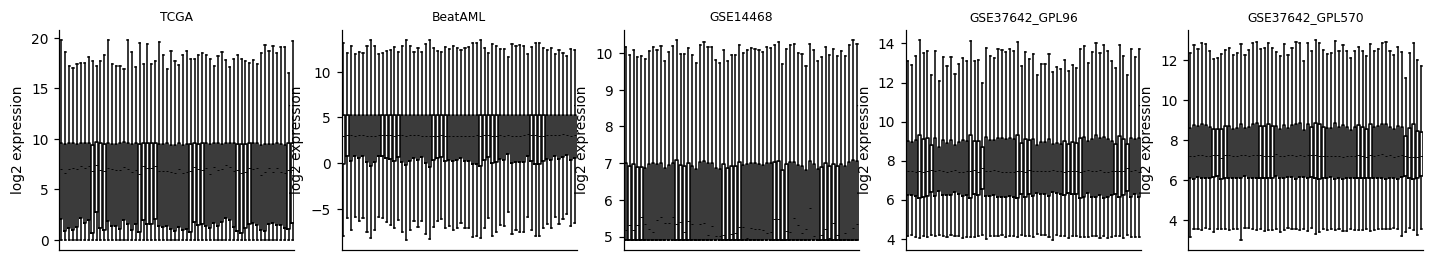

In [13]:
checkpoint('qc = []')
qc = []
for n, c in COHORTS.items():
    e = c['expr']
    qc.append({'cohort': n, **{g: (g in e.index) for g in CFG['HOX_CORE'] + ['CDK9', 'CCNT1', 'HEXIM1']},
               'median_log2': float(np.nanmedian(e.values)), 'pct_missing': float(np.isnan(e.values).mean() * 100)})
qc = pd.DataFrame(qc).set_index('cohort'); save_table(qc, 'QC_gene_availability.csv'); display(qc)

fig, axes = plt.subplots(1, len(COHORTS), figsize=(3.2 * len(COHORTS), 2.6), squeeze=False)
for ax, (n, c) in zip(axes[0], COHORTS.items()):
    sub = c['expr'].iloc[:, :min(60, c['expr'].shape[1])]
    ax.boxplot(sub.values, showfliers=False, widths=.6, medianprops=dict(color='k', lw=.6)); ax.set_xticks([])
    ax.set_title(n, fontsize=8); ax.set_ylabel('log2 expression')
save_fig(fig, 'SuppFig_QC_distributions'); plt.show()

## 5. HOX score and HOX-high calling
* **Primary score:** mean within-cohort z-score of `HOX_CORE` genes present on the platform.
* **Sensitivity scores:** ssGSEA (gseapy) on `HOX_EXT`; PCA PC1 of HOXA cluster.
* **HOX-high call:** two-component Gaussian mixture on the primary score (bimodality is itself evidence for a discrete state — tested by BIC 1 vs 2 components and Hartigan-free bimodality coefficient); tertile and median calls used for sensitivity.

In [14]:
checkpoint('from sklearn.mixture import GaussianMixture')
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

def hox_score(expr, genes):
    g = [x for x in genes if x in expr.index]
    return zscore_rows(expr.loc[g]).mean(0), g

def bimodality_coefficient(x):
    x = pd.Series(x).dropna(); n = len(x); g = stats.skew(x); k = stats.kurtosis(x)
    return (g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3)))   # >0.555 suggests bimodality

def call_hox_high(score, method='gmm'):
    s = score.dropna()
    if method == 'gmm':
        X = s.values.reshape(-1, 1)
        g1 = GaussianMixture(1, random_state=SEED).fit(X); g2 = GaussianMixture(2, random_state=SEED, n_init=10).fit(X)
        hi = int(np.argmax(g2.means_.ravel()))
        post = pd.Series(g2.predict_proba(X)[:, hi], index=s.index)
        call = (post > 0.5).map({True: 'HOX-high', False: 'HOX-low'})
        return call, post, {'BIC_1': g1.bic(X), 'BIC_2': g2.bic(X), 'dBIC': g1.bic(X) - g2.bic(X)}
    q = s.quantile(2/3) if method == 'tertile' else s.median()
    return (s > q).map({True: 'HOX-high', False: 'HOX-low'}), None, {}

def call_anchored(score, anchor):
    s = score.dropna(); a = s[anchor.reindex(s.index).fillna(0) == 1]
    if len(a) < CFG['MIN_ANCHORS']:
        call, post, info = call_hox_high(s, 'gmm'); info.update({'method_used': 'gmm (too few anchors)', 'n_anchors': len(a)})
        return call, post, info
    # robust upper limit of the HOX-low anchor distribution (insensitive to a few mis-annotated anchors)
    thr = np.median(a) + CFG['ANCHOR_K_MAD'] * stats.median_abs_deviation(a, scale='normal')
    return (s > thr).map({True: 'HOX-high', False: 'HOX-low'}), None, {'method_used': 'anchored (median+3MAD)',
            'n_anchors': len(a), 'threshold': thr, 'threshold_p95': np.percentile(a, 95)}

score_stats = []
for n, c in COHORTS.items():
    e, cl = c['expr'], c['clin']
    cl['HOX_score'], used = hox_score(e, CFG['HOX_CORE'])
    hoxa = [g for g in e.index if re.match(r'^HOXA\d+$', g)]
    if len(hoxa) >= 3:
        pc = PCA(1, random_state=SEED).fit(zscore_rows(e.loc[hoxa]).T.fillna(0))
        pc1 = pd.Series(pc.transform(zscore_rows(e.loc[hoxa]).T.fillna(0))[:, 0], index=e.columns)
        cl['HOX_PC1'] = pc1 * np.sign(np.corrcoef(pc1, cl['HOX_score'])[0, 1])
    try:
        import gseapy as gp
        ss = gp.ssgsea(data=e, gene_sets={'HOX_EXT': [g for g in CFG['HOX_EXT'] if g in e.index]},
                       outdir=None, sample_norm_method='rank', no_plot=True, min_size=4, threads=2, seed=SEED)
        r = ss.res2d.pivot(index='Name', columns='Term', values='NES')['HOX_EXT'].astype(float)
        cl['HOX_ssGSEA'] = r.reindex(cl.index)
    except Exception as ex:
        log.warning(f'{n} ssGSEA skipped: {ex}')
    gmm_call, post, bic = call_hox_high(cl['HOX_score'], 'gmm')
    if CFG['HOX_HIGH_METHOD'] == 'anchored':
        call, _, info = call_anchored(cl['HOX_score'], cl['HOXlow_anchor'])
    else:
        call, info = gmm_call, {'method_used': 'gmm'}
    cl['HOX_group'] = call; cl['HOX_post'] = post; cl['HOX_group_gmm'] = gmm_call
    npm = cl['NPM1'] == 1
    info.update({'pct_NPM1mut_called_high': round(100 * (call[npm.reindex(call.index).fillna(False)] == 'HOX-high').mean(), 1) if npm.sum() else np.nan,
                 'pct_anchor_called_high': round(100 * (call[cl['HOXlow_anchor'].reindex(call.index) == 1] == 'HOX-high').mean(), 1)
                                           if cl['HOXlow_anchor'].sum() else np.nan,
                 'pct_high_gmm': round(100 * (gmm_call == 'HOX-high').mean(), 1)})
    cl['HOX_group_tertile'] = call_hox_high(cl['HOX_score'], 'tertile')[0]
    cl['HOX_group_median'] = call_hox_high(cl['HOX_score'], 'median')[0]
    score_stats.append({'cohort': n, 'genes_used': ','.join(used), 'n': len(cl),
                        'HOX_high_n': int((call == 'HOX-high').sum()),
                        'HOX_high_pct': round(100 * (call == 'HOX-high').mean(), 1),
                        'bimodality_coef': round(bimodality_coefficient(cl['HOX_score']), 3), **bic, **info,
                        'kappa_gmm_vs_tertile': round(__import__('sklearn.metrics', fromlist=['cohen_kappa_score'])
                                                      .cohen_kappa_score(call, cl['HOX_group_tertile'].reindex(call.index)), 3)})
    cl.to_csv(os.path.join(P['proc'], f'{n}_annotated_samples.csv'))
score_stats = pd.DataFrame(score_stats).set_index('cohort'); save_table(score_stats, 'Table2_HOX_calling_stats.csv'); score_stats

2026-10-26 18:21:01,876 | INFO | table   Table2_HOX_calling_stats.csv  (5, 16)


,genes_used,n,HOX_high_n,HOX_high_pct,bimodality_coef,BIC_1,BIC_2,dBIC,method_used,n_anchors,threshold,threshold_p95,pct_NPM1mut_called_high,pct_anchor_called_high,pct_high_gmm,kappa_gmm_vs_tertile
cohort,,,,,,,,,,,,,,,,
TCGA,"HOXA5,HOXA6,HOXA7,HOXA9,HOXA10,MEIS1,PBX3",173,121,69.9,0.679,466.152984,392.508015,73.644969,anchored (median+3MAD),33,-0.325387,-0.718123,100.0,3.0,72.8,0.356
BeatAML,"HOXA5,HOXA6,HOXA7,HOXA9,HOXA10,MEIS1,PBX3",591,324,54.8,0.612,1540.002864,1398.585434,141.417430,anchored (median+3MAD),94,0.069936,-0.136499,93.0,3.2,76.5,0.584
GSE14468,"HOXA5,HOXA6,HOXA7,HOXA9,HOXA10,MEIS1,PBX3",461,272,59.0,0.644,1205.351098,1036.154796,169.196302,anchored (median+3MAD),118,-0.393929,-0.636388,100.0,0.8,49.2,0.517
GSE37642_GPL96,"HOXA5,HOXA6,HOXA7,HOXA9,HOXA10,MEIS1,PBX3",422,286,67.8,0.527,1073.312397,1015.761023,57.551375,anchored (median+3MAD),33,-0.577142,-0.887200,NaN,0.0,45.0,0.385
GSE37642_GPL570,"HOXA5,HOXA6,HOXA7,HOXA9,HOXA10,MEIS1,PBX3",140,70,50.0,0.457,368.614318,375.923425,-7.309106,gmm (too few anchors),12,NaN,NaN,NaN,0.0,50.0,0.671


2026-10-26 18:21:13,957 | INFO | maxp pruned
2026-10-26 18:21:13,972 | INFO | cmap pruned
2026-10-26 18:21:13,974 | INFO | kern dropped
2026-10-26 18:21:13,977 | INFO | post pruned
2026-10-26 18:21:13,978 | INFO | FFTM dropped
2026-10-26 18:21:13,982 | INFO | GPOS pruned
2026-10-26 18:21:13,987 | INFO | GSUB pruned
2026-10-26 18:21:13,993 | INFO | glyf pruned
2026-10-26 18:21:13,995 | INFO | Added gid0 to subset
2026-10-26 18:21:13,997 | INFO | Added first four glyphs to subset
2026-10-26 18:21:13,999 | INFO | Closing glyph list over 'MATH': 58 glyphs before
2026-10-26 18:21:14,000 | INFO | Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'L', 'M', 'N', 'O', 'P', 'S', 'T', 'X', 'a', 'b', 'c', 'd', 'e', 'eight', 'equal', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'm', 'minus', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'u', 'underscore', 'w', 'y', 'z', 'ze

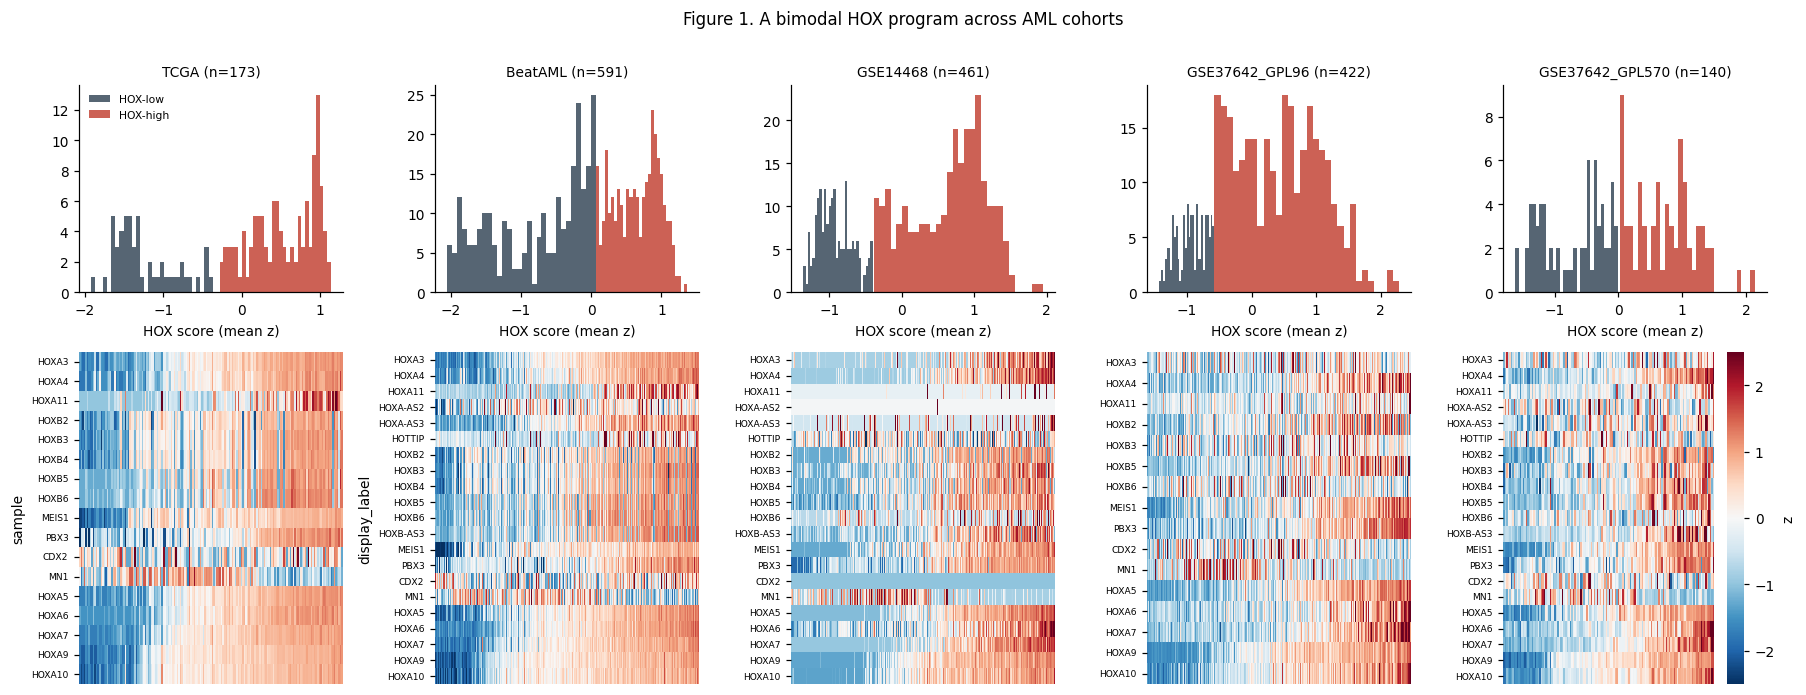

In [15]:
checkpoint('Figure 1: HOX score distribution + heatmap of HOX genes per cohort ---')
# --- Figure 1: HOX score distribution + heatmap of HOX genes per cohort ------------
nC = len(COHORTS)
fig, axes = plt.subplots(2, nC, figsize=(3.3 * nC, 6.2), gridspec_kw={'height_ratios': [1, 1.6]}, squeeze=False)
for j, (n, c) in enumerate(COHORTS.items()):
    cl, e = c['clin'], c['expr']
    ax = axes[0, j]
    for grp_, col in [('HOX-low', PAL['HOX-low']), ('HOX-high', PAL['HOX-high'])]:
        ax.hist(cl.loc[cl['HOX_group'] == grp_, 'HOX_score'], bins=30, color=col, alpha=.8, label=grp_)
    ax.set_title(f'{n} (n={len(cl)})', fontsize=9); ax.set_xlabel('HOX score (mean z)')
    if j == 0: ax.legend(frameon=False, fontsize=7)
    ax = axes[1, j]
    genes = [g for g in CFG['HOX_EXT'] + CFG['HOX_CORE'] if g in e.index]; genes = list(dict.fromkeys(genes))
    order = cl['HOX_score'].sort_values().index
    sns.heatmap(zscore_rows(e.loc[genes, order]).clip(-2.5, 2.5), cmap='RdBu_r', center=0, ax=ax,
                xticklabels=False, yticklabels=genes, cbar=j == nC - 1, cbar_kws={'label': 'z'})
    ax.tick_params(axis='y', labelsize=6)
fig.suptitle('Figure 1. A bimodal HOX program across AML cohorts', y=1.01); fig.tight_layout()
save_fig(fig, 'Fig1_HOX_score_heatmaps'); plt.show()

## 6. HOX-high beyond *NPM1* and *KMT2A* (H2)
* Fraction HOX-high per genotype group in each cohort, with Wilson CIs; random-effects pooled proportion of HOX-high among **Other**.
* Within **Other**, genotype enrichment in HOX-high vs HOX-low (Fisher exact, BH-FDR) — expected candidates: *NUP98*-r, *DNMT3A*, *IDH1/2*, *FLT3*-ITD, *MLLT10*/*KMT2A*-PTD, *CDX2*/*MN1* high, *SET-NUP214*.
* Genotype-adjusted logistic model: `HOX_high ~ NPM1 + KMT2Ar + NUP98r + DNMT3A + FLT3_ITD + IDH1 + IDH2 + age`.

2026-10-26 18:21:22,554 | INFO | table   Table3a_HOXhigh_by_genotype.csv  (10, 7)
2026-10-26 18:21:22,561 | INFO | Pooled HOX-high fraction in NPM1mut: 98.0% (95% CI 86.8–99.7), I2=65%
2026-10-26 18:21:22,567 | INFO | Pooled HOX-high fraction in KMT2Ar: 85.9% (95% CI 73.4–93.1), I2=0%
2026-10-26 18:21:22,571 | INFO | Pooled HOX-high fraction in Other: 42.7% (95% CI 34.2–51.7), I2=83%
2026-10-26 18:21:24,726 | INFO | maxp pruned
2026-10-26 18:21:24,740 | INFO | cmap pruned
2026-10-26 18:21:24,741 | INFO | kern dropped
2026-10-26 18:21:24,742 | INFO | post pruned
2026-10-26 18:21:24,744 | INFO | FFTM dropped
2026-10-26 18:21:24,747 | INFO | GPOS pruned
2026-10-26 18:21:24,754 | INFO | GSUB pruned
2026-10-26 18:21:24,765 | INFO | glyf pruned
2026-10-26 18:21:24,766 | INFO | Added gid0 to subset
2026-10-26 18:21:24,768 | INFO | Added first four glyphs to subset
2026-10-26 18:21:24,769 | INFO | Closing glyph list over 'MATH': 51 glyphs before
2026-10-26 18:21:24,771 | INFO | Glyph names: ['

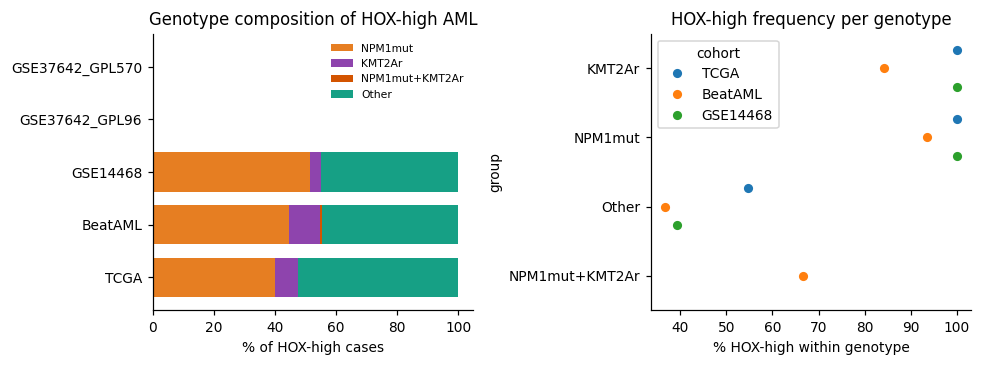

In [16]:
checkpoint('from statsmodels.stats.proportion import proportion_confint')
from statsmodels.stats.proportion import proportion_confint
import statsmodels.api as sm
import statsmodels.formula.api as smf

rows = []
for n, c in COHORTS.items():
    cl = c['clin'].dropna(subset=['genotype_group'])
    for g, d in cl.groupby('genotype_group'):
        k = int((d['HOX_group'] == 'HOX-high').sum()); N = len(d)
        lo, hi = proportion_confint(k, N, method='wilson')
        rows.append({'cohort': n, 'group': g, 'HOX_high': k, 'N': N, 'pct': 100 * k / N, 'ci_lo': 100 * lo, 'ci_hi': 100 * hi})
prop = pd.DataFrame(rows); save_table(prop, 'Table3a_HOXhigh_by_genotype.csv')

# random-effects (DerSimonian–Laird, logit) pooled proportion of HOX-high among "Other"
def pooled_prop(df):
    d = df[(df['N'] > 0)].copy(); d['p'] = (d['HOX_high'] + .5) / (d['N'] + 1)
    d['y'] = np.log(d['p'] / (1 - d['p'])); d['v'] = 1 / (d['N'] * d['p'] * (1 - d['p']))
    w = 1 / d['v']; ybar = (w * d['y']).sum() / w.sum(); Q = (w * (d['y'] - ybar)**2).sum()
    tau2 = max(0, (Q - (len(d) - 1)) / (w.sum() - (w**2).sum() / w.sum())) if len(d) > 1 else 0
    ws = 1 / (d['v'] + tau2); m = (ws * d['y']).sum() / ws.sum(); se = np.sqrt(1 / ws.sum())
    inv = lambda x: 1 / (1 + np.exp(-x))
    I2 = max(0, (Q - (len(d) - 1)) / Q) * 100 if Q > 0 else 0
    return inv(m) * 100, inv(m - 1.96 * se) * 100, inv(m + 1.96 * se) * 100, I2
for g in ['NPM1mut', 'KMT2Ar', 'Other']:
    sub = prop[prop['group'] == g]
    if len(sub):
        m_, l_, h_, i2_ = pooled_prop(sub)
        log.info(f'Pooled HOX-high fraction in {g}: {m_:.1f}% (95% CI {l_:.1f}–{h_:.1f}), I2={i2_:.0f}%')

# Figure 2a — stacked composition of HOX-high cases by genotype
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
comp = pd.concat({n: c['clin'].query("HOX_group=='HOX-high'")['genotype_group'].value_counts(normalize=True)
                  for n, c in COHORTS.items()}, axis=1).T.fillna(0) * 100
comp = comp[[g for g in ['NPM1mut', 'KMT2Ar', 'NPM1mut+KMT2Ar', 'Other'] if g in comp]]
comp.plot(kind='barh', stacked=True, ax=axes[0], color=[PAL[g] for g in comp.columns], width=.75)
axes[0].set_xlabel('% of HOX-high cases'); axes[0].legend(frameon=False, fontsize=7, bbox_to_anchor=(1, 1))
axes[0].set_title('Genotype composition of HOX-high AML')
sns.stripplot(data=prop, x='pct', y='group', hue='cohort', dodge=True, ax=axes[1], size=6)
axes[1].set_xlabel('% HOX-high within genotype'); axes[1].set_title('HOX-high frequency per genotype')
fig.tight_layout(); save_fig(fig, 'Fig2a_genotype_composition'); plt.show()

In [17]:
checkpoint('enrichment within "Other" + adjusted logistic model ------------------')
# --- enrichment within "Other" + adjusted logistic model ---------------------------
enr = []
for n, c in COHORTS.items():
    cl = c['clin']; oth = cl[cl['genotype_group'] == 'Other']
    if len(oth) < 2 * CFG['MIN_GROUP_N']: continue
    for g in [x for x in RECURRENT + ['NUP98r', 'FLT3_ITD'] if x in oth and x != 'NPM1']:
        d = oth[[g, 'HOX_group']].dropna()
        if d[g].sum() < 3: continue
        t = pd.crosstab(d[g] == 1, d['HOX_group'] == 'HOX-high').reindex(index=[True, False], columns=[True, False]).fillna(0)
        OR, p = stats.fisher_exact(t.values)
        enr.append({'cohort': n, 'gene': g, 'mut_in_HOXhigh': int(t.loc[True, True]), 'HOXhigh_n': int(t[True].sum()),
                    'mut_in_HOXlow': int(t.loc[True, False]), 'HOXlow_n': int(t[False].sum()), 'OR': OR, 'p': p})
enr = pd.DataFrame(enr)
if len(enr):
    enr['FDR_within_cohort'] = enr.groupby('cohort')['p'].transform(bh)
    # Fisher-combined p across cohorts per gene
    comb = enr.groupby('gene').agg(n_cohorts=('p', 'size'), median_OR=('OR', 'median'),
                                   p_fisher=('p', lambda x: stats.combine_pvalues(x, method='fisher')[1]))
    comb['FDR'] = bh(comb['p_fisher']); comb = comb.sort_values('p_fisher')
    save_table(enr, 'Table3b_Other_HOXhigh_mutation_enrichment_by_cohort.csv', index=False)
    save_table(comb, 'Table3c_Other_HOXhigh_mutation_enrichment_combined.csv'); display(comb.head(15))

logit_res = []
for n, c in COHORTS.items():
    # fitted within 'Other' only: NPM1mut/KMT2Ar are ~100 % HOX-high (complete separation -> infinite ORs)
    cl = c['clin'][c['clin']['genotype_group'] == 'Other'].copy(); cl['y'] = (cl['HOX_group'] == 'HOX-high').astype(int)
    covs = [v for v in ['NUP98r', 'DNMT3A', 'FLT3_ITD', 'IDH1', 'IDH2', 'TP53', 'RUNX1', 'CEBPA', 'BCOR', 'U2AF1', 'age']
            if v in cl and cl[v].notna().sum() > 0.7 * len(cl) and cl[v].nunique() > 1]
    d = cl[['y'] + covs].dropna()
    covs = [v for v in covs if d[v].nunique() > 1 and (v == 'age' or d[v].sum() >= 5)]
    if len(d) < 50 or not covs: continue
    try:
        m = sm.Logit(d['y'], sm.add_constant(d[covs].astype(float))).fit(disp=0, method='bfgs', maxiter=500)
        ci = np.exp(m.conf_int())
        for v in covs:
            logit_res.append({'cohort': n, 'term': v, 'OR': np.exp(m.params[v]), 'lo': ci.loc[v, 0], 'hi': ci.loc[v, 1], 'p': m.pvalues[v], 'n': len(d)})
    except Exception as ex:
        log.warning(f'{n} logit failed: {ex}')
logit_res = pd.DataFrame(logit_res); save_table(logit_res, 'Table3d_HOXhigh_multivariable_logistic.csv', index=False); logit_res

2026-10-26 18:21:26,793 | INFO | table   Table3b_Other_HOXhigh_mutation_enrichment_by_cohort.csv  (64, 9)
2026-10-26 18:21:27,185 | INFO | table   Table3c_Other_HOXhigh_mutation_enrichment_combined.csv  (34, 4)


,n_cohorts,median_OR,p_fisher,FDR
gene,,,,
DNMT3A,2,3.962086,4.636894e-08,0.000001
IDH2,3,4.634802,8.145630e-08,0.000001
CEBPA,3,0.156648,1.106541e-05,0.000125
FLT3_ITD,3,1.408163,1.874128e-05,0.000159
IDH1,3,5.649123,2.897074e-04,0.001818
BCOR,1,4.105405,3.207807e-04,0.001818
NRAS,2,1.267636,7.360281e-03,0.035750
U2AF1,2,3.802189,9.959197e-03,0.042327
TP53,2,3.452231,3.208579e-02,0.107384


2026-10-26 18:21:28,090 | INFO | table   Table3d_HOXhigh_multivariable_logistic.csv  (23, 7)


,cohort,term,OR,lo,hi,p,n
0,TCGA,DNMT3A,0.927446,0.236264,3.640663,9.140323e-01,115
1,TCGA,FLT3_ITD,1.255587,0.334676,4.710526,7.358240e-01,115
2,TCGA,IDH1,14.851272,1.209538,182.350843,3.497553e-02,115
3,TCGA,IDH2,6.660102,1.072584,41.355214,4.183346e-02,115
4,TCGA,TP53,8.283057,1.393015,49.252191,2.010483e-02,115
5,TCGA,RUNX1,3.955851,0.955042,16.385403,5.789051e-02,115
6,TCGA,CEBPA,0.154690,0.021776,1.098873,6.208186e-02,115
7,TCGA,U2AF1,3.999541,0.386997,41.334542,2.447159e-01,115
8,TCGA,age,1.019369,0.988537,1.051162,2.208638e-01,115
9,BeatAML,DNMT3A,5.678957,2.646462,12.186289,8.266564e-06,349


## 7. The HOX-high transcriptional program and its cross-cohort reproducibility (H1, H3)
1. **Within-cohort DE** HOX-high vs HOX-low (Welch *t* on log2 data, Cohen's *d*, BH-FDR) — run (a) in all patients, (b) in **canonical** (NPM1mut/KMT2Ar) only, (c) in **Other** only.
2. **Reproducibility:** Spearman correlation of *t*-statistics between cohorts; overlap (Jaccard / hypergeometric) of top-ranked genes; Stouffer meta-*z* across cohorts.
3. **"Extends beyond" test:** correlation between the canonical-derived and Other-derived HOX-high program in each cohort, and transfer of a signature learned in canonical cases to classify HOX-high within Other (and across cohorts).
HOX genes in the scoring set are excluded from signatures used for classification to avoid circularity.

In [18]:
checkpoint('def de_two_groups(expr, a_idx, b_idx, min_expr_q=0.2):')
def de_two_groups(expr, a_idx, b_idx, min_expr_q=0.2):
    e = expr.loc[expr.mean(1) > expr.mean(1).quantile(min_expr_q)]
    A, B = e[a_idx], e[b_idx]
    t, p = stats.ttest_ind(A, B, axis=1, equal_var=False, nan_policy='omit')
    lfc = A.mean(1) - B.mean(1)
    sd = np.sqrt(((A.shape[1] - 1) * A.var(1) + (B.shape[1] - 1) * B.var(1)) / (A.shape[1] + B.shape[1] - 2))
    r = pd.DataFrame({'log2FC': lfc, 't': t, 'p': p, 'cohen_d': lfc / sd.replace(0, np.nan),
                      'mean_high': A.mean(1), 'mean_low': B.mean(1)}, index=e.index)
    r['FDR'] = bh(r['p']); return r.sort_values('t', ascending=False)

DE = {}
for n, c in COHORTS.items():
    cl, e = c['clin'], c['expr']
    subsets = {'all': cl.index,
               'canonical': cl.index[cl['genotype_group'].isin(['NPM1mut', 'KMT2Ar', 'NPM1mut+KMT2Ar'])],
               'other': cl.index[cl['genotype_group'] == 'Other']}
    for s, idx in subsets.items():
        hi = idx[cl.loc[idx, 'HOX_group'] == 'HOX-high']; lo = idx[cl.loc[idx, 'HOX_group'] == 'HOX-low']
        if s == 'canonical':   # canonical HOX-high vs HOX-low of ANY genotype (canonical HOX-low is rare)
            lo = cl.index[cl['HOX_group'] == 'HOX-low']
        if min(len(hi), len(lo)) < CFG['MIN_GROUP_N']:
            log.info(f'{n}/{s}: skipped (HOX-high {len(hi)}, HOX-low {len(lo)})'); continue
        DE[(n, s)] = r = de_two_groups(e, hi, lo)
        r.to_csv(os.path.join(P['tab'], f'DE_{n}_{s}_HOXhigh_vs_low.csv'))
        log.info(f'{n}/{s}: hi={len(hi)} lo={len(lo)}; FDR<0.05 & |LFC|>1: '
                 f'{int(((r.FDR < .05) & (r.log2FC.abs() > CFG["LFC_DE"])).sum())}')

2026-10-26 18:21:29,753 | INFO | TCGA/all: hi=121 lo=52; FDR<0.05 & |LFC|>1: 852
2026-10-26 18:21:30,679 | INFO | TCGA/canonical: hi=57 lo=52; FDR<0.05 & |LFC|>1: 1344
2026-10-26 18:21:33,317 | INFO | TCGA/other: hi=63 lo=52; FDR<0.05 & |LFC|>1: 1037
2026-10-26 18:21:34,660 | INFO | BeatAML/all: hi=324 lo=267; FDR<0.05 & |LFC|>1: 508
2026-10-26 18:21:37,869 | INFO | BeatAML/canonical: hi=178 lo=267; FDR<0.05 & |LFC|>1: 1000
2026-10-26 18:21:40,429 | INFO | BeatAML/other: hi=144 lo=248; FDR<0.05 & |LFC|>1: 406
2026-10-26 18:21:41,993 | INFO | GSE14468/all: hi=272 lo=189; FDR<0.05 & |LFC|>1: 92
2026-10-26 18:21:43,943 | INFO | GSE14468/canonical: hi=150 lo=189; FDR<0.05 & |LFC|>1: 175
2026-10-26 18:21:47,066 | INFO | GSE14468/other: hi=122 lo=189; FDR<0.05 & |LFC|>1: 60
2026-10-26 18:21:48,641 | INFO | GSE37642_GPL96/all: hi=286 lo=136; FDR<0.05 & |LFC|>1: 36
2026-10-26 18:21:48,645 | INFO | GSE37642_GPL96/canonical: skipped (HOX-high 0, HOX-low 136)
2026-10-26 18:21:48,648 | INFO | GSE3

In [19]:
checkpoint('reproducibility across cohorts (all-patient contrast) ----------------')
# --- reproducibility across cohorts (all-patient contrast) --------------------------
keys = [k for k in DE if k[1] == 'all']
genes_common = sorted(set.intersection(*[set(DE[k].index) for k in keys])) if keys else []
T = pd.DataFrame({k[0]: DE[k].loc[genes_common, 't'] for k in keys})
corr = T.corr(method='spearman'); save_table(corr, 'Table4a_crosscohort_t_correlation.csv')

def top_set(r, n=200, up=True): return set(r.sort_values('t', ascending=not up).index[:n])
ov = []
for i, a in enumerate(keys):
    for b in keys[i + 1:]:
        U = len(set(DE[a].index) & set(DE[b].index))
        for up in (True, False):
            A, B = top_set(DE[a], up=up) & set(DE[b].index), top_set(DE[b], up=up) & set(DE[a].index)
            k = len(A & B); p = stats.hypergeom.sf(k - 1, U, len(A), len(B))
            ov.append({'A': a[0], 'B': b[0], 'direction': 'up' if up else 'down', 'overlap': k,
                       'jaccard': k / len(A | B), 'expected': len(A) * len(B) / U, 'p_hypergeom': p})
ov = pd.DataFrame(ov); save_table(ov, 'Table4b_crosscohort_top200_overlap.csv', index=False)

# Stouffer meta-z (signed), weighted by sqrt(n)
Z = pd.DataFrame({k[0]: np.sign(DE[k].loc[genes_common, 't']) * stats.norm.isf(DE[k].loc[genes_common, 'p'] / 2) for k in keys})
w = np.array([np.sqrt(COHORTS[k[0]]['expr'].shape[1]) for k in keys])
meta = pd.DataFrame({'meta_z': (Z * w).sum(1) / np.sqrt((w**2).sum()),
                     'n_cohorts_same_sign': (np.sign(Z).eq(np.sign(Z.sum(1)), axis=0)).sum(1),
                     'mean_log2FC': pd.DataFrame({k[0]: DE[k].loc[genes_common, 'log2FC'] for k in keys}).mean(1)})
meta['meta_p'] = 2 * stats.norm.sf(meta['meta_z'].abs()); meta['meta_FDR'] = bh(meta['meta_p'])
meta = meta.sort_values('meta_z', ascending=False)
save_table(meta, 'Table4c_meta_HOXhigh_program.csv')

NK = len(keys)
NMIN = NK - 1 if NK >= 3 else NK      # concordant direction in all but at most one cohort
core_up = meta.query('meta_FDR < 0.01 and mean_log2FC > 0.585 and n_cohorts_same_sign >= @NMIN').index
core_dn = meta.query('meta_FDR < 0.01 and mean_log2FC < -0.585 and n_cohorts_same_sign >= @NMIN').index
HOX_FAMILY = r'^(HOX[ABCD]\d*|HOX[ABCD]-AS\d*|HOTTIP|HOTAIR|HOTAIRM1|MEIS\d|PBX\d|PKNOX\d|CDX\d)$'   # excluded -> no circularity
SIG_UP = [g for g in core_up if not re.match(HOX_FAMILY, g)][:100]
SIG_DN = [g for g in core_dn[::-1] if not re.match(HOX_FAMILY, g)][:100]   # most negative meta-z first
pd.Series(SIG_UP, name='gene').to_csv(os.path.join(P['tab'], 'HOXhigh_reproducible_signature_UP.csv'), index=False)
pd.Series(SIG_DN, name='gene').to_csv(os.path.join(P['tab'], 'HOXhigh_reproducible_signature_DOWN.csv'), index=False)
log.info(f'Reproducible HOX-high program: {len(core_up)} up / {len(core_dn)} down (non-scoring up used: {len(SIG_UP)})')
display(corr.round(2)); display(meta.head(25))

2026-10-26 18:21:51,233 | INFO | table   Table4a_crosscohort_t_correlation.csv  (5, 5)
2026-10-26 18:21:51,915 | INFO | table   Table4b_crosscohort_top200_overlap.csv  (20, 7)
2026-10-26 18:21:54,620 | INFO | table   Table4c_meta_HOXhigh_program.csv  (7718, 5)
2026-10-26 18:21:58,170 | INFO | Reproducible HOX-high program: 105 up / 135 down (non-scoring up used: 92)


,TCGA,BeatAML,GSE14468,GSE37642_GPL96,GSE37642_GPL570
TCGA,1.00,0.25,0.57,0.44,0.33
BeatAML,0.25,1.00,0.51,0.53,0.55
GSE14468,0.57,0.51,1.00,0.53,0.58
GSE37642_GPL96,0.44,0.53,0.53,1.00,0.58
GSE37642_GPL570,0.33,0.55,0.58,0.58,1.00


,meta_z,n_cohorts_same_sign,mean_log2FC,meta_p,meta_FDR
HOXA5,41.567337,5,4.444427,0.000000e+00,0.000000e+00
HOXA9,40.945388,5,4.831516,0.000000e+00,0.000000e+00
HOXA10,37.935228,5,3.272949,0.000000e+00,0.000000e+00
HOXA7,37.758402,5,3.267831,0.000000e+00,0.000000e+00
HOXA4,35.731610,5,2.517356,1.277168e-279,1.971436e-276
HOXA6,34.216470,5,2.935885,1.375783e-256,1.769715e-253
HOXB5,30.961476,5,2.519921,1.780346e-210,1.962959e-207
MEIS1,30.360958,5,3.193837,1.800892e-202,1.737411e-199
PBX3,30.032125,5,2.055269,3.737532e-198,3.205141e-195
HOXA3,26.851783,5,2.567189,8.039816e-159,6.205130e-156


2026-10-26 18:21:58,817 | INFO | table   Table5a_canonical_vs_other_program_concordance.csv  (3, 5)


,cohort,rho_t_canonical_vs_other,p,top200_up_overlap,p_hypergeom
0,TCGA,0.392663,0.0,58,3.867674e-65
1,BeatAML,0.435824,0.0,58,8.864897e-68
2,GSE14468,0.513787,0.0,92,3.248226e-136


2026-10-26 18:22:05,430 | INFO | maxp pruned
2026-10-26 18:22:05,445 | INFO | cmap pruned
2026-10-26 18:22:05,446 | INFO | kern dropped
2026-10-26 18:22:05,448 | INFO | post pruned
2026-10-26 18:22:05,449 | INFO | FFTM dropped
2026-10-26 18:22:05,453 | INFO | GPOS pruned
2026-10-26 18:22:05,458 | INFO | GSUB pruned
2026-10-26 18:22:05,469 | INFO | glyf pruned
2026-10-26 18:22:05,471 | INFO | Added gid0 to subset
2026-10-26 18:22:05,473 | INFO | Added first four glyphs to subset
2026-10-26 18:22:05,475 | INFO | Closing glyph list over 'MATH': 49 glyphs before
2026-10-26 18:22:05,476 | INFO | Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'S', 'T', 'X', 'a', 'e', 'eight', 'equal', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'minus', 'nine', 'nonmarkingreturn', 'o', 'one', 'parenleft', 'parenright', 'period', 'r', 'rho', 'seven', 'six', 'slash', 'space', 't', 'three', 'two', 'zero']
2026-10-26 18:22:05,479 | INFO | Glyph IDs:

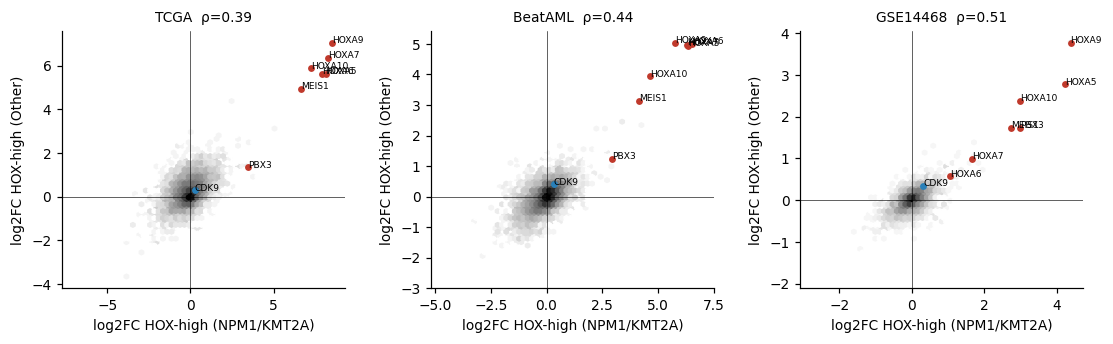

In [20]:
checkpoint('"extends beyond NPM1/KMT2A": canonical vs other program concordance --')
# --- "extends beyond NPM1/KMT2A": canonical vs other program concordance ----------
ext = []
for n in COHORTS:
    if (n, 'canonical') in DE and (n, 'other') in DE:
        a, b = DE[(n, 'canonical')], DE[(n, 'other')]
        g = a.index.intersection(b.index).difference(CFG['HOX_CORE'])
        rho, p = stats.spearmanr(a.loc[g, 't'], b.loc[g, 't'])
        topc = set(a.loc[g].sort_values('t', ascending=False).index[:200])
        topo = set(b.loc[g].sort_values('t', ascending=False).index[:200])
        ext.append({'cohort': n, 'rho_t_canonical_vs_other': rho, 'p': p, 'top200_up_overlap': len(topc & topo),
                    'p_hypergeom': stats.hypergeom.sf(len(topc & topo) - 1, len(g), 200, 200)})
ext = pd.DataFrame(ext); save_table(ext, 'Table5a_canonical_vs_other_program_concordance.csv', index=False); display(ext)

# scatter (Figure 3a)
pairs = [n for n in COHORTS if (n, 'canonical') in DE and (n, 'other') in DE]
if pairs:
    fig, axes = plt.subplots(1, len(pairs), figsize=(3.4 * len(pairs), 3.2), squeeze=False)
    for ax, n in zip(axes[0], pairs):
        a, b = DE[(n, 'canonical')], DE[(n, 'other')]; g = a.index.intersection(b.index)
        ax.hexbin(a.loc[g, 'log2FC'], b.loc[g, 'log2FC'], gridsize=60, bins='log', cmap='Greys', mincnt=1)
        for hg in [x for x in CFG['HOX_CORE'] + ['CDK9'] if x in g]:
            ax.scatter(a.loc[hg, 'log2FC'], b.loc[hg, 'log2FC'], s=12, c=PAL['HOX-high'] if hg != 'CDK9' else '#2980B9')
            ax.annotate(hg, (a.loc[hg, 'log2FC'], b.loc[hg, 'log2FC']), fontsize=6)
        r = ext.set_index('cohort').loc[n, 'rho_t_canonical_vs_other']
        ax.set_title(f'{n}  ρ={r:.2f}', fontsize=9); ax.set_xlabel('log2FC HOX-high (NPM1/KMT2A)'); ax.set_ylabel('log2FC HOX-high (Other)')
        ax.axhline(0, c='k', lw=.4); ax.axvline(0, c='k', lw=.4)
    fig.tight_layout(); save_fig(fig, 'Fig3a_canonical_vs_other_program'); plt.show()

In [21]:
checkpoint('signature transfer: train on TCGA canonical, test on Other + other coh')
# --- signature transfer: train on TCGA canonical, test on Other + other cohorts ----
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def sig_score(e, up, dn):
    z = zscore_rows(e); u = [g for g in up if g in z.index]; d = [g for g in dn if g in z.index]
    return z.loc[u].mean(0) - (z.loc[d].mean(0) if d else 0)

transfer = []
for n, c in COHORTS.items():
    cl = c['clin']; s = sig_score(c['expr'], SIG_UP, SIG_DN); cl['HOXprog_score'] = s
    for subset, idx in [('all', cl.index), ('Other', cl.index[cl['genotype_group'] == 'Other'])]:
        y = (cl.loc[idx, 'HOX_group'] == 'HOX-high').astype(int)
        if y.nunique() < 2 or min(y.sum(), (1 - y).sum()) < 5: continue
        transfer.append({'cohort': n, 'subset': subset, 'n': len(idx), 'AUC_signature_score': roc_auc_score(y, s[idx]),
                         'rho_with_HOXscore': stats.spearmanr(s[idx], cl.loc[idx, 'HOX_score'])[0]})

# strict leave-cohort-out classifier using non-HOX signature genes only
feat = [g for g in SIG_UP + SIG_DN if sum(g in c['expr'].index for c in COHORTS.values()) == len(COHORTS)]
def n_canon(c): return int((c['clin']['genotype_group'].isin(['NPM1mut', 'KMT2Ar']) & (c['clin']['HOX_group'] == 'HOX-high')).sum())
TRAIN = max(COHORTS, key=lambda k: n_canon(COHORTS[k])) if COHORTS else None
log.info(f'Signature classifier training cohort: {TRAIN} ({n_canon(COHORTS[TRAIN]) if TRAIN else 0} canonical HOX-high)')
if len(feat) >= 10 and TRAIN:
    tr = COHORTS[TRAIN]; Xtr = zscore_rows(tr['expr'].loc[feat]).T; ytr = (tr['clin']['HOX_group'] == 'HOX-high').astype(int)
    canon = tr['clin']['genotype_group'].isin(['NPM1mut', 'KMT2Ar']) | (ytr == 0)
    clf = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=10, penalty='l2', cv=5, max_iter=5000, random_state=SEED))
    clf.fit(Xtr[canon], ytr[canon])       # trained ONLY on canonical HOX-high vs HOX-low
    for n, c in COHORTS.items():
        X = zscore_rows(c['expr'].loc[feat]).T; y = (c['clin']['HOX_group'] == 'HOX-high').astype(int)
        for subset, idx in [('all', X.index), ('Other', X.index[c['clin']['genotype_group'] == 'Other'])]:
            if y[idx].nunique() < 2: continue
            transfer.append({'cohort': n, 'subset': subset + f' (classifier trained on {TRAIN} canonical)', 'n': len(idx),
                             'AUC_signature_score': roc_auc_score(y[idx], clf.predict_proba(X.loc[idx])[:, 1])})
transfer = pd.DataFrame(transfer); save_table(transfer, 'Table5b_signature_transfer_AUC.csv', index=False); transfer

2026-10-26 18:22:10,273 | INFO | Signature classifier training cohort: BeatAML (176 canonical HOX-high)
2026-10-26 18:22:10,909 | INFO | table   Table5b_signature_transfer_AUC.csv  (16, 5)


,cohort,subset,n,AUC_signature_score,rho_with_HOXscore
0,TCGA,all,173,0.984266,0.936138
1,TCGA,Other,115,0.971001,0.860215
2,BeatAML,all,591,0.937139,0.895399
3,BeatAML,Other,392,0.886341,0.799936
4,GSE14468,all,461,0.977708,0.906518
5,GSE14468,Other,311,0.955026,0.824274
6,GSE37642_GPL96,all,422,0.945676,0.891675
7,GSE37642_GPL570,all,140,0.959592,0.891771
8,TCGA,all (classifier trained on BeatAML canonical),173,0.909727,NaN
9,TCGA,Other (classifier trained on BeatAML canonical),115,0.832418,NaN


## 8. Pathway biology of the HOX-high program (preranked GSEA, Hallmark + Reactome + KEGG)

2026-10-26 18:31:13,710 [WARNING] Duplicated values found in preranked stats: 6.77% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-26 18:31:20,381 [WARNING] Duplicated values found in preranked stats: 6.77% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-26 18:33:12,732 [WARNING] Duplicated values found in preranked stats: 6.77% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-26 18:33:46,433 [WARNING] Duplicated values found in preranked stats: 6.77% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-26 18:33:52,986 [WARNING] Duplicated values found in preranked stats: 6.77% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-26 18:35:46,237 [WARNING] Duplicated values found in preranked stats: 6.77% of genes
The order of those genes will be

2026-10-26 18:40:05,063 | INFO | table   Table6_GSEA_prerank_all.csv  (11010, 13)
2026-10-26 18:40:08,522 | INFO | maxp pruned
2026-10-26 18:40:08,537 | INFO | cmap pruned
2026-10-26 18:40:08,538 | INFO | kern dropped
2026-10-26 18:40:08,539 | INFO | post pruned
2026-10-26 18:40:08,541 | INFO | FFTM dropped
2026-10-26 18:40:08,546 | INFO | GPOS pruned
2026-10-26 18:40:08,550 | INFO | GSUB pruned
2026-10-26 18:40:08,558 | INFO | glyf pruned
2026-10-26 18:40:08,560 | INFO | Added gid0 to subset
2026-10-26 18:40:08,562 | INFO | Added first four glyphs to subset
2026-10-26 18:40:08,562 | INFO | Closing glyph list over 'MATH': 71 glyphs before
2026-10-26 18:40:08,564 | INFO | Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'X', 'a', 'b', 'c', 'd', 'e', 'eight', 'f', 'five', 'four', 'g', 'greater', 'greaterequal', 'h', 'hyphen', 'i', 'j', 'k', 'l', 'less', 'lessequal', 'm', 'minus', 'n', 'nine', 'nonma

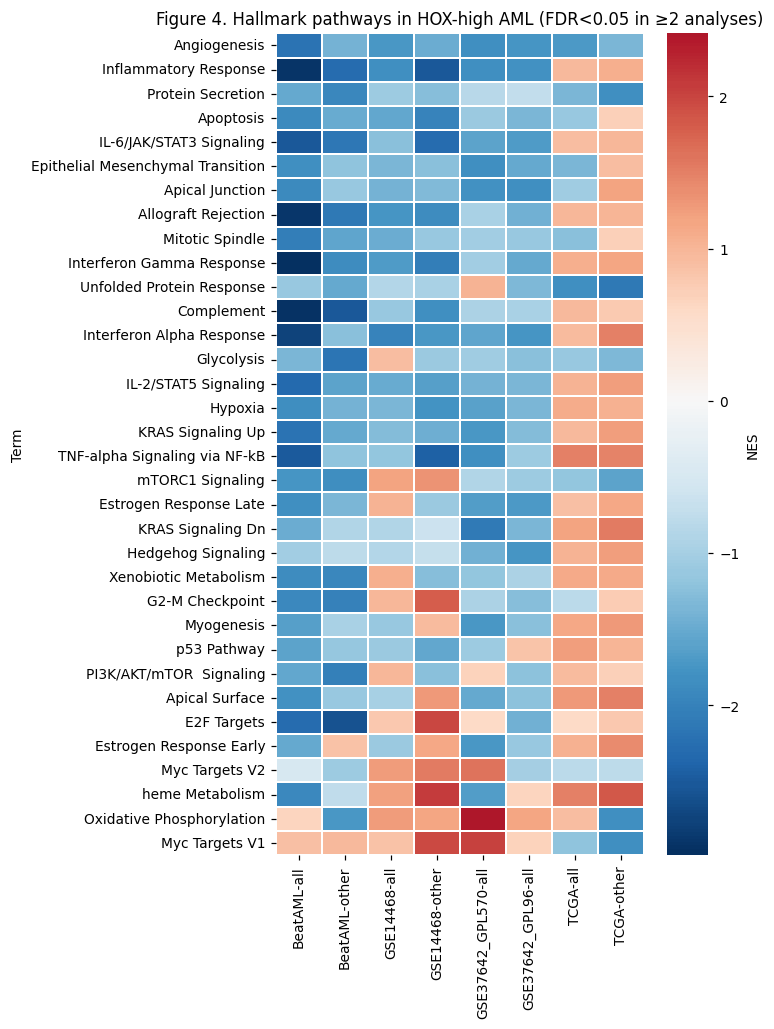

In [22]:
checkpoint('try:')
try:
    import gseapy as gp
except Exception as _e:
    gp = None; log.warning(f'gseapy unavailable ({_e}) — GSEA skipped')
LIBS = ['MSigDB_Hallmark_2020', 'Reactome_2022', 'KEGG_2021_Human']
gsea_all = []
for (n, s), r in (DE.items() if gp is not None else []):
    if s not in ('all', 'other'): continue
    rnk = r['t'].dropna().sort_values(ascending=False)
    rnk = rnk[~rnk.index.duplicated()]
    for lib in LIBS:
        try:
            pre = gp.prerank(rnk=rnk, gene_sets=lib, outdir=None, permutation_num=1000, min_size=15, max_size=500,
                             seed=SEED, threads=4, verbose=False)
            d = pre.res2d.copy(); d['cohort'] = n; d['subset'] = s; d['library'] = lib; gsea_all.append(d)
        except Exception as ex:
            log.warning(f'GSEA {n}/{s}/{lib}: {ex}')
if gsea_all:
    gsea = pd.concat(gsea_all); gsea['NES'] = gsea['NES'].astype(float); gsea['FDR q-val'] = gsea['FDR q-val'].astype(float)
    save_table(gsea, 'Table6_GSEA_prerank_all.csv', index=False)
    hall = gsea[(gsea['library'] == 'MSigDB_Hallmark_2020')]
    piv = hall.pivot_table(index='Term', columns=['cohort', 'subset'], values='NES')
    sig_terms = hall.groupby('Term')['FDR q-val'].apply(lambda x: (x < .05).sum()).loc[lambda x: x >= 2].index
    piv = piv.loc[piv.index.intersection(sig_terms)]
    if len(piv):
        piv = piv.loc[piv.mean(1).sort_values().index]
        fig, ax = plt.subplots(figsize=(1.0 + .55 * piv.shape[1], .25 * len(piv) + 1.2))
        sns.heatmap(piv, cmap='RdBu_r', center=0, ax=ax, cbar_kws={'label': 'NES'}, linewidths=.3)
        ax.set_title('Figure 4. Hallmark pathways in HOX-high AML (FDR<0.05 in ≥2 analyses)'); ax.set_xlabel('')
        save_fig(fig, 'Fig4_Hallmark_GSEA_heatmap'); plt.show()

## 9. Clinical relevance: overall survival (per cohort + inverse-variance meta-analysis)

2026-10-26 18:40:14,054 | INFO | maxp pruned
2026-10-26 18:40:14,069 | INFO | cmap pruned
2026-10-26 18:40:14,070 | INFO | kern dropped
2026-10-26 18:40:14,072 | INFO | post pruned
2026-10-26 18:40:14,073 | INFO | FFTM dropped
2026-10-26 18:40:14,077 | INFO | GPOS pruned
2026-10-26 18:40:14,083 | INFO | GSUB pruned
2026-10-26 18:40:14,089 | INFO | glyf pruned
2026-10-26 18:40:14,091 | INFO | Added gid0 to subset
2026-10-26 18:40:14,092 | INFO | Added first four glyphs to subset
2026-10-26 18:40:14,093 | INFO | Closing glyph list over 'MATH': 47 glyphs before
2026-10-26 18:40:14,094 | INFO | Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'E', 'G', 'H', 'L', 'M', 'O', 'P', 'S', 'T', 'X', 'a', 'e', 'eight', 'equal', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'k', 'l', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'underscore', 'w', 'zero']
2026-10-26 18:40:14,097 | INFO | Glyph IDs:   [0, 1, 2

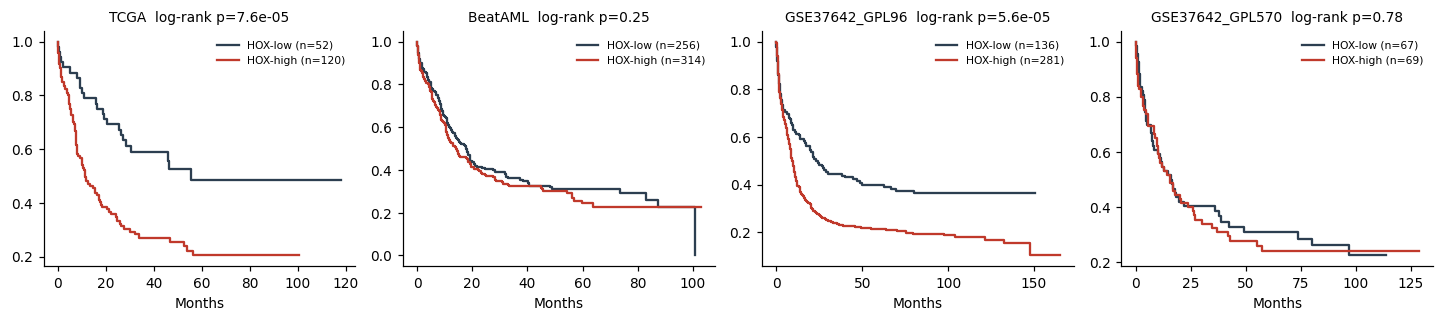

2026-10-26 18:40:15,847 | INFO | table   Table8_Cox_OS_HOXhigh.csv  (23, 11)


,cohort,model,covariates,n,events,HR,lo,hi,p,logHR,se
0,TCGA,univariable,,172.0,113.0,2.389871,1.527896,3.738139,0.000135,0.871240,0.228243
1,TCGA,adjusted,"age,NPM1,FLT3_ITD,KMT2Ar,TP53",171.0,112.0,1.651615,0.989032,2.758081,0.055135,0.501753,0.261628
2,TCGA,adjusted + risk group,"age,NPM1,FLT3_ITD,KMT2Ar,TP53,risk_adverse,ris...",168.0,110.0,0.917212,0.497751,1.690159,0.781704,-0.086417,0.311862
3,TCGA,"univariable, CBF/APL/CEBPAdm excluded",,139.0,102.0,1.316473,0.752252,2.303882,0.335574,0.274956,0.285536
4,TCGA,"adjusted, CBF/APL/CEBPAdm excluded","age,NPM1,FLT3_ITD,KMT2Ar,TP53",138.0,101.0,0.973062,0.529304,1.788856,0.929954,-0.027308,0.310661
5,BeatAML,univariable,,570.0,343.0,1.131287,0.915454,1.398007,0.253412,0.123356,0.108008
6,BeatAML,adjusted,"age,NPM1,FLT3_ITD,KMT2Ar,TP53",524.0,320.0,1.116380,0.865141,1.440578,0.397370,0.110091,0.130081
7,BeatAML,adjusted + risk group,"age,NPM1,FLT3_ITD,KMT2Ar,TP53,risk_adverse,ris...",400.0,223.0,0.812857,0.600320,1.100641,0.180287,-0.207200,0.154642
8,BeatAML,"univariable, CBF/APL/CEBPAdm excluded",,478.0,316.0,0.751421,0.600610,0.940100,0.012406,-0.285789,0.114298
9,BeatAML,"adjusted, CBF/APL/CEBPAdm excluded","age,NPM1,FLT3_ITD,KMT2Ar,TP53",445.0,295.0,0.863560,0.663140,1.124553,0.276270,-0.146692,0.134736


In [23]:
checkpoint('try:')
try:
    from lifelines import KaplanMeierFitter, CoxPHFitter
    from lifelines.statistics import logrank_test
    _LL = True
except Exception as _e:
    _LL = False; log.warning(f'lifelines unavailable ({_e}) — survival skipped')

surv = []; km_cohorts = [n for n, c in COHORTS.items() if _LL and {'OS_months', 'OS_event'} <= set(c['clin']) and c['clin']['OS_event'].notna().sum() > 40]
if km_cohorts:
    fig, axes = plt.subplots(1, len(km_cohorts), figsize=(3.3 * len(km_cohorts), 3), squeeze=False)
    for ax, n in zip(axes[0], km_cohorts):
        cl = COHORTS[n]['clin'].dropna(subset=['OS_months', 'OS_event', 'HOX_group']).query('OS_months > 0')
        for g in ['HOX-low', 'HOX-high']:
            d = cl[cl['HOX_group'] == g]
            KaplanMeierFitter().fit(d['OS_months'], d['OS_event'], label=f'{g} (n={len(d)})').plot_survival_function(ax=ax, ci_show=False, color=PAL[g])
        lr = logrank_test(*[cl.loc[cl['HOX_group'] == g, 'OS_months'] for g in ['HOX-high', 'HOX-low']],
                          *[cl.loc[cl['HOX_group'] == g, 'OS_event'] for g in ['HOX-high', 'HOX-low']])
        ax.set_title(f'{n}  log-rank p={lr.p_value:.2g}', fontsize=9); ax.set_xlabel('Months'); ax.legend(frameon=False, fontsize=7)
        noanc = cl[cl['HOXlow_anchor'] != 1]          # excludes favourable CBF-AML / APL / CEBPA-dm reference cases
        for model, covs, dat in [('univariable', [], cl), ('adjusted', ['age', 'NPM1', 'FLT3_ITD', 'KMT2Ar', 'TP53'], cl),
                                 ('adjusted + risk group', ['age', 'NPM1', 'FLT3_ITD', 'KMT2Ar', 'TP53', 'risk_adverse', 'risk_favorable'], cl),
                                 ('univariable, CBF/APL/CEBPAdm excluded', [], noanc),
                                 ('adjusted, CBF/APL/CEBPAdm excluded', ['age', 'NPM1', 'FLT3_ITD', 'KMT2Ar', 'TP53'], noanc)]:
            covs = [v for v in covs if v in dat and dat[v].notna().mean() > .7 and dat[v].nunique() > 1]
            if model == 'adjusted + risk group' and not any(v.startswith('risk_') for v in covs): continue
            d = dat[['OS_months', 'OS_event'] + covs].copy(); d['HOX_high'] = (dat['HOX_group'] == 'HOX-high').astype(int)
            d = d.dropna()
            try:
                cph = CoxPHFitter(penalizer=0.01).fit(d, 'OS_months', 'OS_event')
                s = cph.summary.loc['HOX_high']
                surv.append({'cohort': n, 'model': model, 'covariates': ','.join(covs), 'n': len(d), 'events': int(d['OS_event'].sum()),
                             'HR': s['exp(coef)'], 'lo': s['exp(coef) lower 95%'], 'hi': s['exp(coef) upper 95%'], 'p': s['p'],
                             'logHR': s['coef'], 'se': s['se(coef)']})
            except Exception as ex: log.warning(f'Cox {n}/{model}: {ex}')
    fig.tight_layout(); save_fig(fig, 'Fig7_KM_HOXhigh'); plt.show()
surv = pd.DataFrame(surv)
if len(surv):
    for m in surv['model'].unique():
        d = surv[surv['model'] == m]; w = 1 / d['se']**2; b = (w * d['logHR']).sum() / w.sum(); se = np.sqrt(1 / w.sum())
        surv = pd.concat([surv, pd.DataFrame([{'cohort': 'META (fixed, IV)', 'model': m, 'HR': np.exp(b), 'lo': np.exp(b - 1.96 * se),
                                               'hi': np.exp(b + 1.96 * se), 'p': 2 * stats.norm.sf(abs(b / se))}])])
    save_table(surv, 'Table8_Cox_OS_HOXhigh.csv', index=False); display(surv)

## 10. CDK9 and the P-TEFb module in HOX-high AML (H4)
CDK9 expression HOX-high vs HOX-low per cohort and **within genotype strata** (so the effect is not merely NPM1-driven); correlation with HOX score; P-TEFb module score; Stouffer meta-analysis.

2026-10-26 18:40:17,157 | INFO | table   Table9_CDK9_PTEFb_by_HOX.csv  (152, 11)


,cohort,gene,stratum,n_high,n_low,log2FC,p_MWU,AUC_effect,rho_HOXscore,p_rho,FDR
0,TCGA,CDK9,all,121,52,0.274777,3.145405e-03,0.641847,0.209846,5.588359e-03,2.078702e-02
1,TCGA,CDK9,Other,63,52,0.292925,2.643757e-03,0.663462,0.262717,4.560408e-03,1.826596e-02
34,BeatAML,CDK9,all,324,267,0.351498,2.043702e-13,0.675429,0.356830,3.467875e-19,3.106428e-11
35,BeatAML,CDK9,NPM1mut,144,10,0.153814,5.874058e-01,0.551736,0.587557,1.145874e-15,8.043755e-01
36,BeatAML,CDK9,Other,144,248,0.401188,1.763429e-12,0.713570,0.381020,5.430258e-15,8.934709e-11
85,GSE14468,CDK9,all,272,189,0.330813,1.751707e-11,0.684057,0.321714,1.465019e-12,6.656486e-10
86,GSE14468,CDK9,Other,122,189,0.346447,6.765482e-08,0.681260,0.287981,2.365464e-07,1.713922e-06
119,GSE37642_GPL96,CDK9,all,286,136,0.150767,3.512493e-04,0.607607,0.215425,8.014640e-06,3.813563e-03
135,GSE37642_GPL570,CDK9,all,70,70,0.157714,2.493705e-02,0.609898,0.228023,6.736184e-03,8.216261e-02


2026-10-26 18:40:20,520 | INFO | maxp pruned
2026-10-26 18:40:20,534 | INFO | cmap pruned
2026-10-26 18:40:20,535 | INFO | kern dropped
2026-10-26 18:40:20,536 | INFO | post pruned
2026-10-26 18:40:20,538 | INFO | FFTM dropped
2026-10-26 18:40:20,542 | INFO | GPOS pruned
2026-10-26 18:40:20,545 | INFO | GSUB pruned
2026-10-26 18:40:20,553 | INFO | glyf pruned
2026-10-26 18:40:20,554 | INFO | Added gid0 to subset
2026-10-26 18:40:20,556 | INFO | Added first four glyphs to subset
2026-10-26 18:40:20,557 | INFO | Closing glyph list over 'MATH': 53 glyphs before
2026-10-26 18:40:20,559 | INFO | Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'K', 'L', 'M', 'O', 'P', 'S', 'T', 'X', 'a', 'comma', 'd', 'e', 'eight', 'equal', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'u', 'underscore', 'uni0394', 'w', 'zero']
2026-10-26 18:

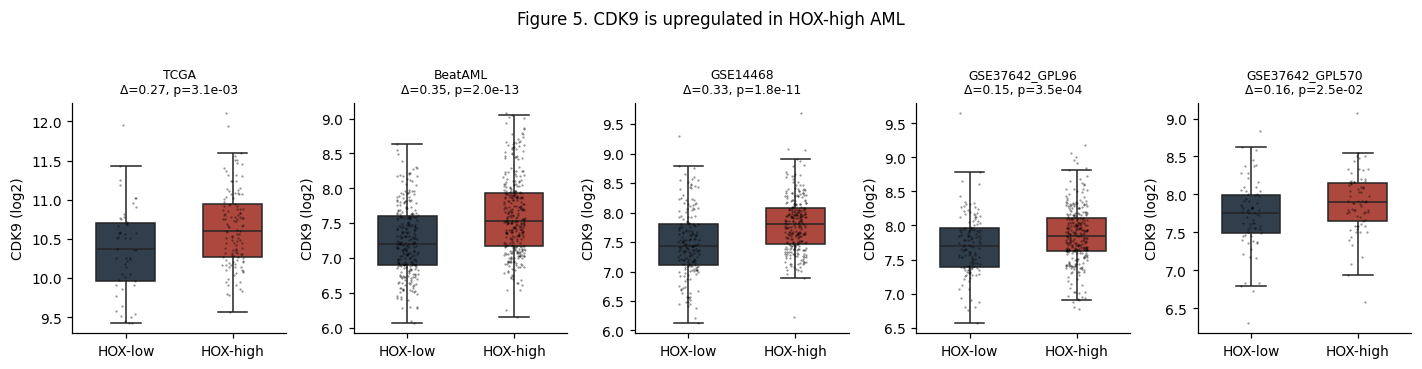

In [24]:
checkpoint('cdk = []')
cdk = []
for n, c in COHORTS.items():
    e, cl = c['expr'], c['clin']
    if 'CDK9' not in e.index: continue
    cl['CDK9'] = e.loc['CDK9']; cl['PTEFb_score'] = zscore_rows(e.loc[[g for g in CFG['PTEFB'] if g in e.index]]).mean(0)
    for gene in [g for g in CFG['PTEFB'] + CFG['CDK9_TARGETS'] if g in e.index]:
        for stratum, idx in [('all', cl.index)] + [(g, cl.index[cl['genotype_group'] == g]) for g in ['NPM1mut', 'Other']]:
            hi = idx[cl.loc[idx, 'HOX_group'] == 'HOX-high']; lo = idx[cl.loc[idx, 'HOX_group'] == 'HOX-low']
            if min(len(hi), len(lo)) < 5: continue
            u, p = stats.mannwhitneyu(e.loc[gene, hi], e.loc[gene, lo])
            rho, prho = stats.spearmanr(e.loc[gene, idx], cl.loc[idx, 'HOX_score'])
            cdk.append({'cohort': n, 'gene': gene, 'stratum': stratum, 'n_high': len(hi), 'n_low': len(lo),
                        'log2FC': e.loc[gene, hi].mean() - e.loc[gene, lo].mean(), 'p_MWU': p,
                        'AUC_effect': u / (len(hi) * len(lo)), 'rho_HOXscore': rho, 'p_rho': prho})
cdk = pd.DataFrame(cdk); cdk['FDR'] = bh(cdk['p_MWU']); save_table(cdk, 'Table9_CDK9_PTEFb_by_HOX.csv', index=False)
display(cdk.query("gene=='CDK9'"))

d9 = [n for n, c in COHORTS.items() if 'CDK9' in c['clin']]
fig, axes = plt.subplots(1, len(d9), figsize=(2.6 * len(d9), 3.2), squeeze=False)
for ax, n in zip(axes[0], d9):
    cl = COHORTS[n]['clin'].dropna(subset=['HOX_group'])
    sns.boxplot(data=cl, x='HOX_group', y='CDK9', order=['HOX-low', 'HOX-high'], palette=PAL, ax=ax, fliersize=0, width=.55)
    sns.stripplot(data=cl, x='HOX_group', y='CDK9', order=['HOX-low', 'HOX-high'], color='k', size=1.5, alpha=.4, ax=ax)
    r = cdk.query("cohort==@n and gene=='CDK9' and stratum=='all'")
    if len(r): ax.set_title(f'{n}\nΔ={r.log2FC.iloc[0]:.2f}, p={r.p_MWU.iloc[0]:.1e}', fontsize=8)
    ax.set_xlabel(''); ax.set_ylabel('CDK9 (log2)')
fig.suptitle('Figure 5. CDK9 is upregulated in HOX-high AML', y=1.03); fig.tight_layout()
save_fig(fig, 'Fig5_CDK9_HOXhigh'); plt.show()

## 11. Is CDK9 upregulation coupled to CDK9-inhibitor sensitivity? — BeatAML ex vivo (H5)
For each CDK9 inhibitor in the BeatAML panel (AUC; lower = more sensitive):
* AUC ~ HOX group (Mann–Whitney, Cliff's δ) and Spearman AUC vs CDK9 expression, P-TEFb score and HOX score.
* Multivariable linear model: `AUC ~ CDK9 + HOX_score + NPM1 + FLT3_ITD + age` (standardized β).
* **Uncoupling evidence** is not just p > 0.05: we report bootstrap 95 % CIs of ρ and an equivalence test (TOST, bounds |ρ| < 0.2) plus the minimum detectable ρ at 80 % power.
* **Positive controls** must replicate (FLT3-ITD → FLT3-inhibitor sensitivity; NPM1 → venetoclax), otherwise the null result is not interpretable.

In [25]:
checkpoint('def cliffs_delta(a, b):')
def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b); return (np.sign(a[:, None] - b[None, :])).mean()

def boot_rho(x, y, B=2000):
    x, y = np.asarray(x), np.asarray(y); rng = np.random.default_rng(SEED); n = len(x); r = []
    for _ in range(B):
        i = rng.integers(0, n, n); r.append(stats.spearmanr(x[i], y[i])[0])
    return np.nanpercentile(r, [2.5, 97.5])

def tost_rho(rho, n, bound=0.2):
    z, se = np.arctanh(rho), 1 / np.sqrt(n - 3)
    p1 = stats.norm.sf((z - np.arctanh(-bound)) / se); p2 = stats.norm.cdf((z - np.arctanh(bound)) / se)
    return max(p1, p2)

def mdr(n, alpha=.05, power=.8):
    return np.tanh((stats.norm.isf(alpha / 2) + stats.norm.isf(1 - power)) / np.sqrt(n - 3))

drug_res = []
if beat_auc is not None and 'BeatAML' in COHORTS:
    cl = COHORTS['BeatAML']['clin']
    # map AUC sample IDs to the RNA-seq sample IDs used in expression
    idcol = next((c for c in ['dbgap_rnaseq_sample', 'dbgap_subject_id', 'lab_id', 'dbgap_dnaseq_sample'] if c in beat_auc), None)
    auc = beat_auc.pivot_table(index=idcol, columns='inhibitor', values='auc', aggfunc='mean')
    if len(auc.index.intersection(cl.index)) < 50 and BEAT.get('clin'):
        cmap = pd.read_excel(BEAT['clin'])
        if idcol in cmap and 'dbgap_rnaseq_sample' in cmap:
            m = cmap.dropna(subset=[idcol, 'dbgap_rnaseq_sample']).drop_duplicates(idcol).set_index(idcol)['dbgap_rnaseq_sample']
            auc = auc.rename(index=m)
    # cBioPortal BeatAML sample IDs can differ from dbGaP IDs; try a relaxed match
    if len(auc.index.intersection(cl.index)) < 50:
        norm = lambda s: re.sub(r'[^0-9A-Za-z]', '', str(s)).upper()
        mp = {norm(i): i for i in cl.index}; auc.index = [mp.get(norm(i), i) for i in auc.index]
    shared = auc.index.intersection(cl.index)
    log.info(f'BeatAML samples with both RNA-seq and drug AUC: {len(shared)}')
    save_table(auc.loc[shared], 'BeatAML_AUC_matrix_matched.csv')

    test_drugs = {d: 'CDK9i' for d in auc.columns if re.search(CFG['CDK9_INHIB_REGEX'], d, re.I)}
    for ctrl, rgx in CFG['POS_CTRL'].items():
        test_drugs.update({d: f'POSCTRL_{ctrl}' for d in auc.columns if re.search(rgx, d, re.I)})
    for drug, cls in test_drugs.items():
        d = cl.loc[shared].assign(AUC=auc.loc[shared, drug]).dropna(subset=['AUC'])
        if len(d) < 30: continue
        row = {'drug': drug, 'class': cls, 'n': len(d)}
        if cls == 'CDK9i':
            hi, lo = d.loc[d.HOX_group == 'HOX-high', 'AUC'], d.loc[d.HOX_group == 'HOX-low', 'AUC']
            row.update({'AUC_HOXhigh_median': hi.median(), 'AUC_HOXlow_median': lo.median(),
                        'p_HOX_MWU': stats.mannwhitneyu(hi, lo)[1] if min(len(hi), len(lo)) > 4 else np.nan,
                        'cliffs_delta_HOX': cliffs_delta(hi, lo) if min(len(hi), len(lo)) > 4 else np.nan})
            for v in ['CDK9', 'PTEFb_score', 'HOX_score', 'MCL1' if 'MCL1' in COHORTS['BeatAML']['expr'].index else None]:
                if v is None: continue
                x = d[v] if v in d else COHORTS['BeatAML']['expr'].loc[v, d.index]
                rho, p = stats.spearmanr(x, d['AUC']); lo_, hi_ = boot_rho(x.values, d['AUC'].values)
                row.update({f'rho_{v}': rho, f'p_{v}': p, f'rho_{v}_CI': f'[{lo_:.2f}, {hi_:.2f}]', f'TOST_p_{v}': tost_rho(rho, len(d))})
            row['min_detectable_rho_80pct'] = mdr(len(d))
            covs = [v for v in ['CDK9', 'HOX_score', 'NPM1', 'FLT3_ITD', 'age'] if v in d and d[v].notna().mean() > .7]
            dd = d[['AUC'] + covs].dropna(); dz = (dd - dd.mean()) / dd.std()
            try:
                ols = smf.ols('AUC ~ ' + ' + '.join(covs), data=dz).fit()
                for v in covs: row[f'beta_{v}'] = ols.params[v]; row[f'p_beta_{v}'] = ols.pvalues[v]
            except Exception as ex: log.warning(f'OLS {drug}: {ex}')
        else:
            g = cls.replace('POSCTRL_', '')
            if g in d and d[g].nunique() == 2:
                a, b = d.loc[d[g] == 1, 'AUC'], d.loc[d[g] == 0, 'AUC']
                row.update({'genotype': g, 'AUC_mut_median': a.median(), 'AUC_wt_median': b.median(),
                            'p_genotype_MWU': stats.mannwhitneyu(a, b)[1], 'cliffs_delta_genotype': cliffs_delta(a, b)})
        drug_res.append(row)
drug_res = pd.DataFrame(drug_res); save_table(drug_res, 'Table7_BeatAML_CDK9i_and_positive_controls.csv', index=False)
display(drug_res)

2026-10-26 18:40:22,081 | INFO | BeatAML samples with both RNA-seq and drug AUC: 452
2026-10-26 18:40:23,083 | INFO | table   BeatAML_AUC_matrix_matched.csv  (452, 165)
2026-10-26 18:40:44,936 | INFO | table   Table7_BeatAML_CDK9i_and_positive_controls.csv  (10, 39)


,drug,class,n,AUC_HOXhigh_median,AUC_HOXlow_median,p_HOX_MWU,cliffs_delta_HOX,rho_CDK9,p_CDK9,rho_CDK9_CI,...,p_beta_NPM1,beta_FLT3_ITD,p_beta_FLT3_ITD,beta_age,p_beta_age,genotype,AUC_mut_median,AUC_wt_median,p_genotype_MWU,cliffs_delta_genotype
0,AT7519,CDK9i,387,129.824278,132.461372,0.084828,-0.102510,0.132664,0.008977,"[0.03, 0.23]",...,0.618543,-0.058430,0.278001,0.037563,0.468321,NaN,NaN,NaN,NaN,NaN
1,Flavopiridol,CDK9i,391,112.785495,104.750491,0.169013,0.081443,0.150438,0.002862,"[0.05, 0.25]",...,0.111661,0.032259,0.556150,0.008330,0.873623,NaN,NaN,NaN,NaN,NaN
2,Roscovitine (CYC-202),CDK9i,402,260.418704,268.461956,0.003985,-0.168624,-0.098720,0.047929,"[-0.20, -0.00]",...,0.670988,-0.191745,0.000404,-0.023405,0.647639,NaN,NaN,NaN,NaN,NaN
3,SNS-032 (BMS-387032),CDK9i,398,82.827131,95.025018,0.005629,-0.162729,0.080377,0.109363,"[-0.01, 0.18]",...,0.321115,-0.111829,0.036833,0.042708,0.400952,NaN,NaN,NaN,NaN,NaN
4,Crenolanib,POSCTRL_FLT3_ITD,385,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,FLT3_ITD,174.017651,230.945431,3.249328e-15,-0.540543
5,Gilteritinib,POSCTRL_FLT3_ITD,238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,FLT3_ITD,107.644203,152.162121,2.098510e-06,-0.395653
6,Midostaurin,POSCTRL_FLT3_ITD,403,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,FLT3_ITD,175.510769,212.383601,3.123757e-10,-0.420953
7,Quizartinib (AC220),POSCTRL_FLT3_ITD,401,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,FLT3_ITD,111.505736,160.392411,8.047099e-15,-0.523603
8,Sorafenib,POSCTRL_FLT3_ITD,430,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,FLT3_ITD,146.301420,202.793466,4.563671e-20,-0.591505
9,Venetoclax,POSCTRL_NPM1,319,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NPM1,147.620693,162.135284,3.361676e-01,-0.068139


2026-10-26 18:40:45,669 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-26 18:40:45,675 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-26 18:40:50,034 | INFO | maxp pruned
2026-10-26 18:40:50,049 | INFO | cmap pruned
2026-10-26 18:40:50,050 | INFO | kern dropped
2026-10-26 18:40:50,053 | INFO | post pruned
2026-10-26 18:40:50,054 | INFO | FFTM dropped
2026-10-26 18:40:50,058 | INFO | GPOS pruned
2026-10-26 18:40:50,064 | INFO | GSUB pruned
2026-10-26 18:40:50,071 | INFO | glyf pruned
2026-10-26 18:40:50,073 | INFO | Added gid0 to subset
2026-10-26 18:40:50,075 | INFO | Added first four glyphs to subset
2026-10-26 18:40:50,076 | INFO | Closing glyph list over 'MATH': 67 gly

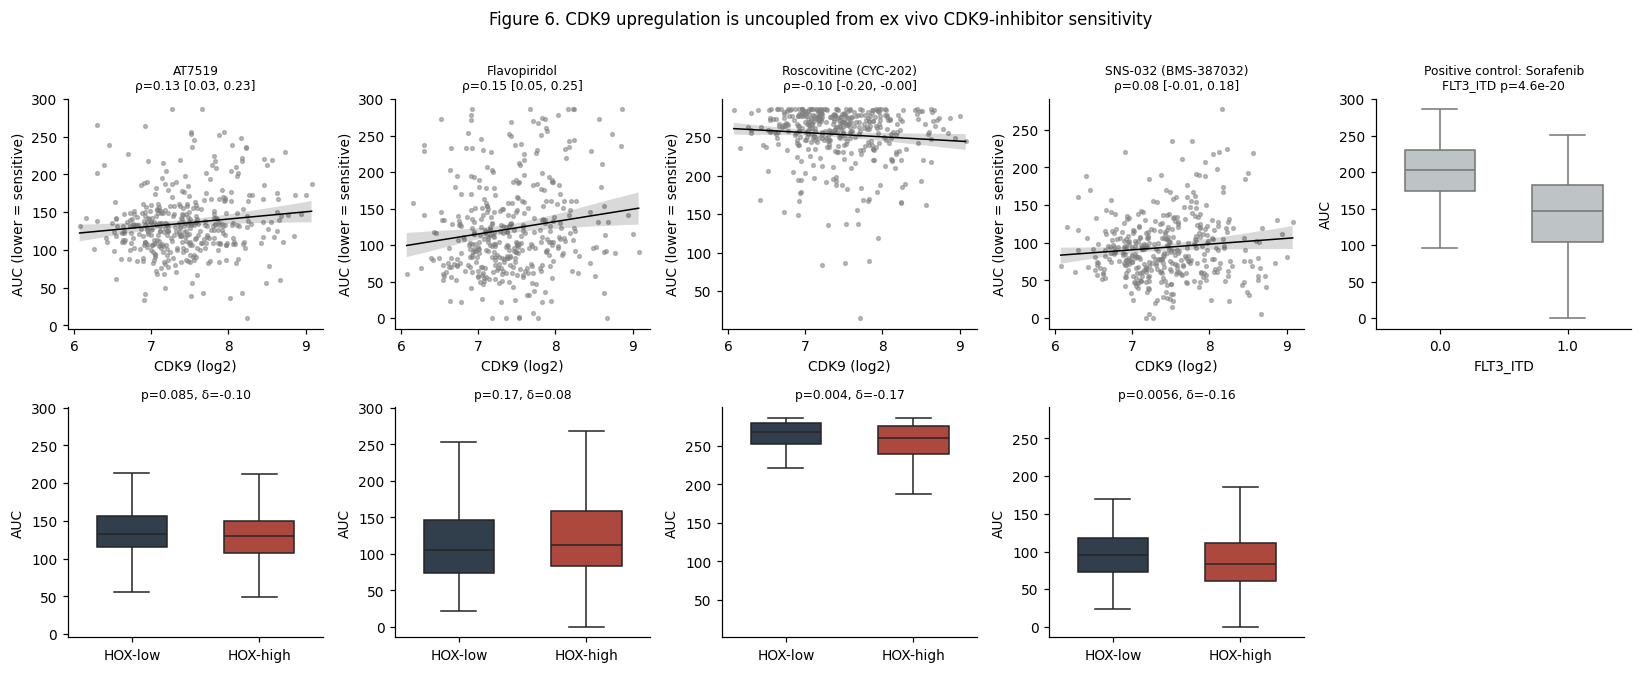

In [26]:
checkpoint('Figure 6: CDK9 expression vs CDK9-inhibitor AUC; HOX group vs AUC; pos')
# --- Figure 6: CDK9 expression vs CDK9-inhibitor AUC; HOX group vs AUC; positive control ----
if len(drug_res) and (drug_res['class'] == 'CDK9i').any():
    cdk9i = drug_res.query("`class`=='CDK9i'")['drug'].tolist()[:4]
    pc = drug_res.query("`class`!='CDK9i'").sort_values('p_genotype_MWU').head(1)
    ncol = len(cdk9i) + (1 if len(pc) else 0)
    fig, axes = plt.subplots(2, ncol, figsize=(3.0 * ncol, 6), squeeze=False)
    for j, drug in enumerate(cdk9i):
        d = cl.loc[shared].assign(AUC=auc.loc[shared, drug]).dropna(subset=['AUC', 'CDK9'])
        ax = axes[0, j]; sns.regplot(data=d, x='CDK9', y='AUC', ax=ax, scatter_kws=dict(s=6, alpha=.5, color='grey'), line_kws=dict(color='k', lw=1))
        r = drug_res.set_index('drug').loc[drug]
        ax.set_title(f'{drug}\nρ={r.rho_CDK9:.2f} {r.rho_CDK9_CI}', fontsize=8); ax.set_xlabel('CDK9 (log2)'); ax.set_ylabel('AUC (lower = sensitive)')
        ax = axes[1, j]; sns.boxplot(data=d, x='HOX_group', y='AUC', order=['HOX-low', 'HOX-high'], palette=PAL, ax=ax, fliersize=0, width=.55)
        ax.set_title(f'p={r.p_HOX_MWU:.2g}, δ={r.cliffs_delta_HOX:.2f}', fontsize=8); ax.set_xlabel('')
    if len(pc):
        drug, g = pc['drug'].iloc[0], pc['genotype'].iloc[0]
        d = cl.loc[shared].assign(AUC=auc.loc[shared, drug]).dropna(subset=['AUC', g])
        ax = axes[0, -1]; sns.boxplot(data=d, x=g, y='AUC', ax=ax, fliersize=0, color='#BDC3C7', width=.55)
        ax.set_title(f'Positive control: {drug}\n{g} p={pc.p_genotype_MWU.iloc[0]:.1e}', fontsize=8); axes[1, -1].axis('off')
    fig.suptitle('Figure 6. CDK9 upregulation is uncoupled from ex vivo CDK9-inhibitor sensitivity', y=1.01)
    fig.tight_layout(); save_fig(fig, 'Fig6_BeatAML_CDK9i_uncoupling'); plt.show()

## 12. Orthogonal cell-line evidence — DepMap CRISPR dependency, PRISM and GDSC2 (H5)
In myeloid/AML cell lines: (i) is CDK9 a pan-essential dependency independent of HOX status? (ii) does CDK9 mRNA predict CDK9 gene effect or CDK9-inhibitor AUC/IC50? HOX status of lines is called with the same HOX score (expected HOX-high: MOLM-13, MV4-11, OCI-AML3, THP-1, NOMO-1; HOX-low: Kasumi-1, NB4, HL-60, KG-1).

In [27]:
checkpoint('dep_res = []')
dep_res = []
try:
    model = pd.read_csv(DEP['model']).set_index('ModelID')
    # strict: DepMap primary disease = acute myeloid leukemia (v1 regex 'AM' also matched non-myeloid lines)
    aml = model[model.get('OncotreePrimaryDisease', pd.Series(index=model.index, dtype=str)).astype(str)
                .str.fullmatch(r'Acute Myeloid Leukemia', case=False)]
    ex = pd.read_csv(DEP['expr'], index_col=0, low_memory=False)
    if 'IsDefaultEntryForModel' in ex.columns: ex = ex[ex['IsDefaultEntryForModel'].astype(str).str.lower().isin(['yes', 'true', '1'])]
    if 'ModelID' in ex.columns: ex = ex.set_index('ModelID')
    ex = ex[~ex.index.duplicated()]
    ex = ex.select_dtypes('number'); ex.columns = [c.split(' (')[0] for c in ex.columns]
    ex = ex.loc[ex.index.intersection(aml.index)]
    ge = pd.read_csv(DEP['gene_effect'], index_col=0); ge.columns = [c.split(' (')[0] for c in ge.columns]
    lines = pd.DataFrame(index=ex.index)
    lines['name'] = aml.loc[lines.index, 'StrippedCellLineName'] if 'StrippedCellLineName' in aml else lines.index
    lines['HOX_score'] = hox_score(ex.T, CFG['HOX_CORE'])[0]
    lines['HOX_group'] = np.where(lines['HOX_score'] > lines['HOX_score'].median(), 'HOX-high', 'HOX-low')
    lines['CDK9_expr'] = ex.get('CDK9'); lines['CDK9_effect'] = ge.reindex(lines.index).get('CDK9')
    all_ge_cdk9 = ge['CDK9'].dropna()
    log.info(f'AML lines: {len(lines)}; CDK9 gene effect median AML={lines.CDK9_effect.median():.2f} vs all lines={all_ge_cdk9.median():.2f}')
    d = lines.dropna(subset=['CDK9_effect', 'CDK9_expr'])
    for v in ['CDK9_expr', 'HOX_score']:
        rho, p = stats.spearmanr(d[v], d['CDK9_effect']); dep_res.append({'source': 'DepMap CRISPR', 'x': v, 'y': 'CDK9_effect', 'n': len(d), 'rho': rho, 'p': p})
    # PRISM CDK9 inhibitors
    if DEP.get('prism_auc'):
        pr = pd.read_csv(DEP['prism_auc'], low_memory=False)
        namecol = next((c for c in ['name', 'Drug.Name', 'compound_name', 'drug_name'] if c in pr), None)
        cellcol = next((c for c in ['depmap_id', 'ModelID', 'row_name', 'DepMap_ID'] if c in pr), None)
        auccol = next((c for c in ['auc', 'AUC', 'Auc'] if c in pr), None)
        if namecol and cellcol and auccol:
            pr = pr[pr[namecol].astype(str).str.contains(CFG['CDK9_INHIB_REGEX'], case=False, regex=True)]
            for drug, dd in pr.groupby(namecol):
                x = dd.groupby(cellcol)[auccol].mean().reindex(lines.index).dropna()
                if len(x) < 8: continue
                for v in ['CDK9_expr', 'HOX_score']:
                    rho, p = stats.spearmanr(lines.loc[x.index, v], x)
                    dep_res.append({'source': 'PRISM', 'drug': drug, 'x': v, 'y': 'AUC', 'n': len(x), 'rho': rho, 'p': p})
    lines.to_csv(os.path.join(P['proc'], 'DepMap_AML_lines_HOX_CDK9.csv'))
except Exception as ex_:
    log.warning(f'DepMap analysis skipped: {ex_}')

try:
    if GDSC:
        gd = pd.read_excel(GDSC)
        gd = gd[gd['DRUG_NAME'].astype(str).str.contains(CFG['CDK9_INHIB_REGEX'], case=False, regex=True)]
        if 'lines' in globals() and len(gd):
            mp = model['SangerModelID'].dropna() if 'SangerModelID' in model else pd.Series(dtype=str)
            inv = pd.Series(mp.index, index=mp.values); inv = inv[~inv.index.duplicated()]
            gd['ModelID'] = gd['SANGER_MODEL_ID'].map(inv)
            for drug, dd in gd.groupby('DRUG_NAME'):
                x = dd.groupby('ModelID')['LN_IC50'].mean(); x = x[x.index.isin(lines.index)].dropna()
                if len(x) < 8: continue
                for v in ['CDK9_expr', 'HOX_score']:
                    rho, p = stats.spearmanr(lines.loc[x.index, v], x)
                    dep_res.append({'source': 'GDSC2', 'drug': drug, 'x': v, 'y': 'LN_IC50', 'n': len(x), 'rho': rho, 'p': p})
except Exception as ex_:
    log.warning(f'GDSC analysis skipped: {ex_}')
dep_res = pd.DataFrame(dep_res)
if len(dep_res): dep_res['FDR'] = bh(dep_res['p'])
save_table(dep_res, 'Table10_cellline_CDK9_dependency_and_inhibitor_sensitivity.csv', index=False); dep_res

2026-10-26 18:41:18,474 | INFO | AML lines: 54; CDK9 gene effect median AML=-1.51 vs all lines=-1.42
2026-10-26 18:41:56,665 | INFO | table   Table10_cellline_CDK9_dependency_and_inhibitor_sensitivity.csv  (4, 8)


,source,x,y,n,rho,p,drug,FDR
0,DepMap CRISPR,CDK9_expr,CDK9_effect,29,0.091626,0.636419,NaN,0.988626
1,DepMap CRISPR,HOX_score,CDK9_effect,29,-0.140887,0.466018,NaN,0.988626
2,GDSC2,CDK9_expr,LN_IC50,19,0.003509,0.988626,Dinaciclib,0.988626
3,GDSC2,HOX_score,LN_IC50,19,0.049123,0.841712,Dinaciclib,0.988626


## 13. Robustness and sensitivity analyses
* HOX-high definition: GMM vs tertile vs median vs ssGSEA-based GMM — re-compute the key statistics (H2 % HOX-high in Other; H4 CDK9 log2FC).
* Leave-one-gene-out HOX score (correlation with the full score).
* TCGA/BeatAML restricted to *de novo* AML / bone-marrow samples where annotation exists.

In [28]:
checkpoint('rob = []')
rob = []
for n, c in COHORTS.items():
    cl, e = c['clin'], c['expr']
    defs = {'primary_' + CFG['HOX_HIGH_METHOD']: cl['HOX_group'], 'gmm': cl['HOX_group_gmm'],
            'tertile': cl['HOX_group_tertile'], 'median': cl['HOX_group_median']}
    if 'HOX_ssGSEA' in cl and cl['HOX_ssGSEA'].notna().sum() > 30:
        defs['ssgsea_gmm'] = call_hox_high(cl['HOX_ssGSEA'], 'gmm')[0]
    for k, g in defs.items():
        g = g.reindex(cl.index); row = {'cohort': n, 'definition': k, 'pct_HOXhigh': 100 * (g == 'HOX-high').mean()}
        oth = cl['genotype_group'] == 'Other'
        if oth.sum(): row['pct_HOXhigh_in_Other'] = 100 * (g[oth] == 'HOX-high').mean()
        if 'CDK9' in e.index:
            row['CDK9_log2FC'] = e.loc['CDK9', g == 'HOX-high'].mean() - e.loc['CDK9', g == 'HOX-low'].mean()
            row['CDK9_p'] = stats.mannwhitneyu(e.loc['CDK9', g == 'HOX-high'], e.loc['CDK9', g == 'HOX-low'])[1]
        rob.append(row)
    used = [x for x in CFG['HOX_CORE'] if x in e.index]
    for gx in used:
        s = hox_score(e, [x for x in used if x != gx])[0]
        rob.append({'cohort': n, 'definition': f'LOGO_minus_{gx}', 'rho_vs_full_score': stats.spearmanr(s, cl['HOX_score'])[0]})
rob = pd.DataFrame(rob); save_table(rob, 'Table11_robustness.csv', index=False); rob

2026-10-26 18:41:57,868 | INFO | table   Table11_robustness.csv  (60, 7)


,cohort,definition,pct_HOXhigh,pct_HOXhigh_in_Other,CDK9_log2FC,CDK9_p,rho_vs_full_score
0,TCGA,primary_anchored,69.942197,54.782609,0.274777,3.145405e-03,NaN
1,TCGA,gmm,72.832370,59.130435,0.312049,8.147492e-04,NaN
2,TCGA,tertile,33.526012,6.086957,0.168942,1.027038e-01,NaN
3,TCGA,median,49.710983,26.956522,0.204380,2.446767e-02,NaN
4,TCGA,ssgsea_gmm,28.323699,4.347826,0.210753,5.375809e-02,NaN
5,TCGA,LOGO_minus_HOXA5,NaN,NaN,NaN,NaN,0.997977
6,TCGA,LOGO_minus_HOXA6,NaN,NaN,NaN,NaN,0.997937
7,TCGA,LOGO_minus_HOXA7,NaN,NaN,NaN,NaN,0.998315
8,TCGA,LOGO_minus_HOXA9,NaN,NaN,NaN,NaN,0.998292
9,TCGA,LOGO_minus_HOXA10,NaN,NaN,NaN,NaN,0.997397


## 13b. Reviewer round 1 (biomedicines-4694076) — CDK9 by genotype group (Reviewer 2, Figure 5A)
Reviewer 2 asked (i) to add NPM1-mutated / KMT2A-rearranged patients as a comparison group for CDK9 and (ii) to compare CDK9 expression of HOX-high patients overall with HOX-high patients without NPM1/KMT2A lesions. Because the overall HOX-high group contains the non-canonical cases, (ii) is tested as canonical versus non-canonical HOX-high (independent groups). We also (iii) fit CDK9 ~ HOX-high + canonical genotype (+ reference-subtype flag) and (iv) repeat the HOX-high vs HOX-low comparison after excluding the HOX-low reference subtypes (CBF-AML, APL, CEBPA double-mutant), which could otherwise drive the difference. Patient-level CDK9 values are exported so that the manuscript figure can be redrawn outside Colab.

In [ ]:
checkpoint('13b reviewer R1: CDK9 by genotype group')
import sys, platform
import statsmodels.formula.api as smf
log.info(f'Python {sys.version.split()[0]} | {platform.platform()}')
r1_rows, r1_lm, r1_pat = [], [], []
GENO = ['TCGA', 'BeatAML', 'GSE14468']           # cohorts with NPM1/KMT2A annotation
for n in GENO:
    c = COHORTS.get(n)
    if c is None or 'CDK9' not in c['expr'].index: continue
    e, cl = c['expr'], c['clin'].copy()
    cl['CDK9'] = e.loc['CDK9', cl.index]
    canon = cl['genotype_group'].isin(['NPM1mut', 'KMT2Ar', 'NPM1mut+KMT2Ar'])
    other = cl['genotype_group'] == 'Other'
    hi, lo = cl['HOX_group'] == 'HOX-high', cl['HOX_group'] == 'HOX-low'
    ref = cl['HOXlow_anchor'].fillna(0).astype(int) == 1
    grp = pd.Series(np.nan, index=cl.index, dtype=object)
    grp[hi & canon] = 'HOX-high canonical'; grp[hi & other] = 'HOX-high NPM1-wt/KMT2A-nr'
    grp[lo & canon] = 'HOX-low canonical'; grp[lo & other & ~ref] = 'HOX-low non-reference'; grp[lo & ref] = 'HOX-low reference'
    r1_pat.append(pd.DataFrame({'cohort': n, 'sample': cl.index, 'CDK9': cl['CDK9'].values, 'HOX_score': cl['HOX_score'].values,
                                'HOX_group': cl['HOX_group'].values, 'genotype_group': cl['genotype_group'].values,
                                'HOXlow_reference': ref.astype(int).values, 'plot_group': grp.values}))
    x = cl['CDK9']
    def comp(label, a, b):
        a, b = x[a].dropna(), x[b].dropna()
        if min(len(a), len(b)) < 5: return
        u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        r1_rows.append({'cohort': n, 'comparison': label, 'n_a': len(a), 'n_b': len(b), 'mean_a': a.mean(), 'mean_b': b.mean(),
                        'log2FC': a.mean() - b.mean(), 'fold_change': 2 ** (a.mean() - b.mean()),
                        'AUC_effect': u / (len(a) * len(b)), 'p_MWU': p})
    comp('HOX-high (all) vs HOX-low (all)', hi, lo)                                    # = Table9 'all'
    comp('HOX-high canonical vs HOX-low (all)', hi & canon, lo)
    comp('HOX-high NPM1-wt/KMT2A-nr vs HOX-low (all)', hi & other, lo)
    comp('HOX-high NPM1-wt/KMT2A-nr vs HOX-low NPM1-wt/KMT2A-nr', hi & other, lo & other)   # = Table9 'Other'
    comp('HOX-high canonical vs HOX-high NPM1-wt/KMT2A-nr', hi & canon, hi & other)
    comp('HOX-high (all) vs HOX-low, reference subtypes excluded', hi & ~ref, lo & ~ref)
    comp('HOX-high NPM1-wt/KMT2A-nr vs HOX-low NPM1-wt/KMT2A-nr, reference excluded', hi & other & ~ref, lo & other & ~ref)
    comp('NPM1mut HOX-high vs NPM1mut HOX-low', hi & (cl['genotype_group'] == 'NPM1mut'), lo & (cl['genotype_group'] == 'NPM1mut'))
    d = pd.DataFrame({'CDK9': x, 'HOXhigh': hi.astype(int), 'canonical': canon.astype(int), 'reference': ref.astype(int)}).dropna()
    d = d[cl.loc[d.index, 'genotype_group'].notna()]
    for form in ['CDK9 ~ HOXhigh + canonical', 'CDK9 ~ HOXhigh + canonical + reference']:
        f = smf.ols(form, data=d).fit()
        for term in f.params.index.drop('Intercept'):
            r1_lm.append({'cohort': n, 'model': form, 'term': term, 'beta_log2': f.params[term],
                          'ci_low': f.conf_int().loc[term, 0], 'ci_high': f.conf_int().loc[term, 1], 'p': f.pvalues[term], 'n': int(f.nobs)})
r1 = pd.DataFrame(r1_rows); r1['FDR'] = bh(r1['p_MWU'])
r1_lm = pd.DataFrame(r1_lm); r1_pat = pd.concat(r1_pat, ignore_index=True)
save_table(r1, 'R1_TableR1_CDK9_by_genotype_group.csv', index=False)
save_table(r1_lm, 'R1_TableR2_CDK9_linear_models.csv', index=False)
save_table(r1_pat, 'R1_TableR3_CDK9_patient_level.csv', index=False)
display(r1.round(4)); display(r1_lm.round(4))

order = ['HOX-low reference', 'HOX-low non-reference', 'HOX-high NPM1-wt/KMT2A-nr', 'HOX-high canonical']
fig, axes = plt.subplots(1, len(GENO), figsize=(4.2 * len(GENO), 3.6), squeeze=False)
for ax, n in zip(axes[0], GENO):
    d = r1_pat[(r1_pat.cohort == n) & r1_pat.plot_group.isin(order)]
    sns.boxplot(data=d, x='plot_group', y='CDK9', order=order, ax=ax, fliersize=0, width=.6, color='#dddddd')
    sns.stripplot(data=d, x='plot_group', y='CDK9', order=order, ax=ax, size=1.6, alpha=.5, color='k')
    ax.set_title(n, fontsize=9); ax.set_xlabel(''); ax.set_ylabel('CDK9 (log2)')
    ax.set_xticklabels([f"{o}\n(n={int((d.plot_group == o).sum())})" for o in order], rotation=30, ha='right', fontsize=7)
fig.tight_layout(); save_fig(fig, 'FigR1_CDK9_by_genotype_group'); plt.show()


# Sensitivity of the pooled non-canonical HOX-high fraction to NUP98 rearrangements (same pooled_prop() as section 6)
nup = []
for n in GENO:
    cl = COHORTS[n]['clin']; d = cl[(cl['genotype_group'] == 'Other') & (cl.get('NUP98r', pd.Series(0, index=cl.index)).fillna(0) != 1)]
    nup.append({'cohort': n, 'group': 'Other_noNUP98r', 'HOX_high': int((d['HOX_group'] == 'HOX-high').sum()), 'N': len(d)})
nup = pd.DataFrame(nup); m_, l_, h_, i2_ = pooled_prop(nup)
log.info(f'Pooled HOX-high fraction in Other without NUP98r: {m_:.1f}% (95% CI {l_:.1f}–{h_:.1f}), I2={i2_:.0f}%')
nup.loc[len(nup)] = {'cohort': 'pooled', 'group': f'{m_:.1f} ({l_:.1f}-{h_:.1f}); I2={i2_:.0f}', 'HOX_high': nup.HOX_high.sum(), 'N': nup.N.sum()}
save_table(nup, 'R1_TableR4_Other_noNUP98r_pooled.csv', index=False)


## 14. Results digest, methods text, figure/table index and archive

In [29]:
checkpoint('def g(df, q, col, fmt={:.2f}):')
def g(df, q, col, fmt='{:.2f}'):
    try: return fmt.format(df.query(q)[col].iloc[0])
    except Exception: return 'NA'

lines_ = [f'# HOX-high AML — automated results digest (run {RUN_ID})', '',
          '## Cohorts', summary.to_markdown() if hasattr(summary, 'to_markdown') else str(summary), '',
          '## H1 — HOX-high state', score_stats.to_markdown(), '',
          f'Cross-cohort Spearman correlation of HOX-high t-statistics (median): {np.nanmedian(corr.values[np.triu_indices_from(corr, 1)]):.2f}' if len(corr) > 1 else '',
          f'Reproducible program: {len(core_up)} up / {len(core_dn)} down genes (meta-FDR<0.01, |mean LFC|>0.585, same direction in >= {NMIN} cohorts; signature = {len(SIG_UP)} up + {len(SIG_DN)} strongest down non-HOX genes).', '',
          '## H2 — beyond NPM1/KMT2A', prop.round(1).to_markdown(index=False), '',
          '## H3 — canonical vs other program', ext.round(3).to_markdown(index=False) if len(ext) else 'NA', '',
          transfer.round(3).to_markdown(index=False) if len(transfer) else '', '',
          '## H4 — CDK9', cdk.query("gene=='CDK9'").round(4).to_markdown(index=False) if len(cdk) else 'NA', '',
          '## H5 — CDK9 inhibitors (BeatAML)', drug_res.round(3).to_markdown(index=False) if len(drug_res) else 'NA', '',
          '## H5 — cell lines', dep_res.round(3).to_markdown(index=False) if len(dep_res) else 'NA', '',
          '## Survival', surv.round(3).to_markdown(index=False) if len(surv) else 'NA']
open(os.path.join(P['rep'], f'Results_digest_{RUN_ID}.md'), 'w').write('\n'.join(map(str, lines_)))

methods = f'''# Methods (auto-generated draft — edit before submission)

**Data sources.** Bulk transcriptomes and clinical/genomic annotations were obtained from TCGA-LAML (PanCancer Atlas),
BeatAML 2.0 (waves 1–4), the HOVON cohort (GSE14468) and the AMLCG cohort (GSE37642); TARGET-AML was used as a pediatric
extension. Ex vivo drug sensitivity (area under the dose–response curve, AUC) was taken from the BeatAML 2.0 release.
Cell-line CRISPR gene effects, expression and PRISM drug sensitivity were obtained from DepMap; GDSC2 provided independent
IC50 values. All analyses used publicly available, de-identified data.

**Pre-processing.** RNA-seq values were log2(x+1)-transformed where required; microarray probes were mapped to gene symbols
and collapsed to the probe with the highest mean expression. All scores were computed within cohort on row z-scored data.

**Genotype harmonization.** NPM1 and other recurrent mutations were taken from curated clinical annotations (PCR/fragment
analysis) when available and otherwise from sequencing calls (TCGA via the cBioPortal API); BeatAML was restricted to AML
specimens, one per patient (initial-diagnosis specimen preferred); KMT2A rearrangements were identified from structural-variant/fusion calls and cytogenetic
text (11q23 / KMT2A partner translocations; KMT2A-PTD excluded). Patients were classified as NPM1mut, KMT2Ar or Other.

**HOX score and HOX-high calling.** The HOX score was the mean z-score of {", ".join(CFG["HOX_CORE"])}. Because score
distributions differ between RNA-seq and microarray platforms, HOX-high status was calibrated within each cohort against
subtypes known to lack HOXA/MEIS1 expression (core-binding-factor AML, acute promyelocytic leukemia and CEBPA double-mutant
AML): samples scoring above the median + 3 × MAD (normal-scaled) of these reference cases were classified as HOX-high.
Cohorts with fewer than {CFG["MIN_ANCHORS"]} reference cases used a two-component Gaussian mixture model (posterior > 0.5).
Bimodality was assessed by ΔBIC and the bimodality coefficient; GMM, tertile, median and ssGSEA-based definitions were used
as sensitivity analyses. Affymetrix probes annotated to several genes were assigned to each gene before collapsing; platforms
lacking the HOX core genes (U133B) were excluded.

**Differential expression and reproducibility.** HOX-high versus HOX-low comparisons used Welch t-tests with Benjamini–Hochberg
correction. Reproducibility was quantified by between-cohort Spearman correlation of t-statistics, hypergeometric overlap of
top-200 genes, and a sqrt(n)-weighted Stouffer meta-analysis. A reproducible program was defined as genes with meta-FDR < 0.01,
mean |log2FC| > 1 and concordant direction in all cohorts. To test whether the program extends beyond NPM1/KMT2A alterations,
contrasts were repeated in canonical and Other patients separately and compared; an L2-regularized logistic classifier trained
on TCGA canonical cases (scoring genes excluded) was applied to Other patients and to independent cohorts (ROC AUC).

**Pathways.** Preranked GSEA (gseapy, 1,000 permutations) was run against MSigDB Hallmark, Reactome and KEGG.

**Survival.** Overall survival was compared by Kaplan–Meier/log-rank and Cox proportional-hazards models (univariable and
adjusted for age, NPM1, FLT3-ITD, KMT2Ar and TP53 where available), pooled by fixed-effect inverse-variance meta-analysis.

**CDK9 and drug response.** CDK9 and P-TEFb module expression were compared between HOX groups overall and within genotype
strata (Mann–Whitney U). Associations between CDK9-inhibitor AUC and CDK9 expression, P-TEFb score and HOX score were assessed
by Spearman correlation with 2,000-sample bootstrap CIs, equivalence testing (TOST, |ρ| < 0.2) and multivariable linear models.
Established drug–genotype associations (FLT3-ITD/FLT3 inhibitors; NPM1/venetoclax) served as positive controls. Cell-line
analyses repeated these tests in DepMap/PRISM and GDSC2 AML lines.

**Software.** Python {platform.python_version()}, pandas {pd.__version__}, numpy {np.__version__}, scipy, statsmodels, scikit-learn,
lifelines, gseapy, GEOparse. Random seed {SEED}. Code and full outputs are archived with this notebook.
'''
open(os.path.join(P['rep'], 'Methods_draft.md'), 'w').write(methods)

idx_rows = [{'type': 'figure' if f.endswith('.png') else 'table', 'file': os.path.relpath(f, PROJECT)}
            for f in sorted(glob.glob(os.path.join(P['fig'], '*.png')) + glob.glob(os.path.join(P['tab'], '*')))]
pd.DataFrame(idx_rows).to_csv(os.path.join(P['rep'], 'Output_index.csv'), index=False)

# key tables in one workbook
with pd.ExcelWriter(os.path.join(P['rep'], f'HOX_AML_key_tables_{RUN_ID}.xlsx')) as xw:
    for name, df in [('T1_cohorts', summary), ('T2_HOXcalling', score_stats), ('T3a_HOXbyGenotype', prop),
                     ('T4c_meta_program', meta.head(500)), ('T5a_canon_vs_other', ext), ('T5b_transfer', transfer),
                     ('T7_BeatAML_drugs', drug_res), ('T8_Cox', surv), ('T9_CDK9', cdk), ('T10_celllines', dep_res), ('T11_robust', rob)]:
        if isinstance(df, pd.DataFrame) and len(df): df.to_excel(xw, sheet_name=name[:31])

# software versions + copy of the notebook itself
import subprocess
open(os.path.join(P['log'], 'pip_freeze.txt'), 'w').write(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)
for nbp in glob.glob('/content/*.ipynb') + glob.glob('/content/drive/MyDrive/Colab Notebooks/*HOX*AML*.ipynb'):
    shutil.copy(nbp, P['code'])
zpath = os.path.join(PROJECT, f'HOX_AML_outputs_{RUN_ID}.zip')
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for sub in ['02_tables', '03_figures', '04_logs', '05_reports']:
        for f in glob.glob(os.path.join(PROJECT, sub, '*')): z.write(f, os.path.relpath(f, PROJECT))
log.info(f'DONE. Everything is in {PROJECT}  (archive: {os.path.basename(zpath)})')

2026-10-26 18:42:33,772 | INFO | DONE. Everything is in /content/drive/MyDrive/Bengisu_HOX_AML  (archive: HOX_AML_outputs_20261026_1817.zip)


---
### Interpretation guide (for writing the Results)
* **Calibration QC first:** in `Table2`, `pct_anchor_called_high` should be ≲ 10 % and `pct_NPM1mut_called_high` ≳ 90 %; otherwise the HOX-high call is not trustworthy in that cohort.
* **H1 supported** if ΔBIC > 10 and bimodality coefficient > 0.555 in most cohorts **and** median cross-cohort ρ of *t*-statistics > 0.5.
* **H2 supported** if the pooled HOX-high fraction in **Other** is clearly > 0 (CI excludes ~5 %) and replicates in ≥ 2 cohorts; Table 3c names the genotypes driving it (*NUP98*-r, *DNMT3A*, *IDH*, *MLLT10*, etc.).
* **H3 supported** if canonical-vs-Other ρ > 0.5 and the TCGA-canonical classifier reaches AUC > 0.85 on Other patients in independent cohorts.
* **H4 supported** if CDK9 log2FC > 0 with FDR < 0.05 in ≥ 2 cohorts, including within the Other stratum.
* **H5 ("uncoupled") supported** only if (a) positive controls replicate, (b) CDK9-inhibitor AUC shows |ρ| < 0.2 with CI inside ±0.2 / TOST p < 0.05 for CDK9 expression, and (c) the cell-line analyses agree. A merely non-significant ρ with wide CI should be reported as *inconclusive*, not *uncoupled*.

### Known limitations to state
Cohort-level genotype annotation is heterogeneous (GEO cohorts lack full mutation panels); BeatAML CDK9-inhibitor coverage depends on the panel version (flavopiridol/SNS-032/AT7519 have different off-target CDK profiles); ex vivo AUC reflects 72-h viability, not transcriptional target engagement (MCL1/MYC suppression).

In [31]:
import glob, os
from google.colab import files
zips = sorted(glob.glob('/content/drive/MyDrive/Bengisu_HOX_AML/**/HOX_AML_outputs_*.zip', recursive=True),
              key=os.path.getmtime)
print(zips[-1], round(os.path.getsize(zips[-1])/1e6, 1), 'MB')
files.download(zips[-1])

/content/drive/MyDrive/Bengisu_HOX_AML/HOX_AML_outputs_20261026_1817.zip 21.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>